# Driver Drowsiness Detection on UL-DD: full pipeline and model comparison

**What this notebook does**, in order: reads the UL-DD *Extracted_Features* files (FAU, FL, PL), cleans them, cuts them into labelled 10-second windows, runs EDA, then trains and compares classical ML, ANN, 1D-CNN, RNN, LSTM, GRU, Transformer, CNN-BiLSTM and two image models (VGG16, InceptionV3), all on the **same subject-wise folds**.



| Section | Topic |
|---|---|
| 0-1 | Setup and configuration |
| 2 | Labels (KSS to classes) |
| 3 | Reading the feature files, layout checks |
| 4-5 | Per-frame signals, cleaning, per-subject normalisation |
| 6 | Windowing, label assignment, feature tables, cache |
| 7 | EDA |
| 8 | Subject-wise cross-validation and metrics |
| 9 | Classical ML |
| 10 | ANN |
| 11 | CNN, RNN, LSTM, GRU, Transformer, CNN-BiLSTM on sequences |
| 12 | VGG16 and InceptionV3 on IR face frames |
| 13 | Comparison, ablation, saved results |

## 0. Setup

In [ ]:
import os, re, sys, glob, time, json, hashlib, warnings, random, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

try:
    from google.colab import drive
    drive.mount("/content/drive/")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Running in Colab:", IN_COLAB)

#  chart style
FAMILY_COLOR = {"ML": "#2a78d6", "ANN": "#eb6834", "Sequence DL": "#1baf7a", "Image DL": "#eda100"}
CLASS_COLORS = ["#9ec5f0", "#4f8fe0", "#1a4f99"]      # ordered classes: light -> dark blue for nature of drowsiness
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#bdbcb6",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
})

Mounted at /content/drive/
Running in Colab: True


## 1. Configuration

Everything you may want to change is in this one cell. The values below follow the dataset paper where it states them (60 fps, 40-minute sessions, one KSS score per 4 minutes) and are otherwise my design choices, explained in the companion doc.

In [ ]:
#  Paths
DATA_ROOT   = Path("/content/drive/MyDrive/")
FEATURE_DIR = DATA_ROOT / "Extracted_Features"
VIDEO_DIR   = DATA_ROOT / "Video_Data"
LABELS_CSV  = DATA_ROOT / "Labels.csv"
CACHE_DIR   = DATA_ROOT / "cache"
OUT_DIR     = DATA_ROOT / "results"

# run size
QUICK_MODE = False
RUN_IMAGE_MODELS = True
RUN_ABLATION = True

# Data layout (from the dataset paper)
FPS = 60
INTERVAL_MIN = 4
N_INTERVALS = 10
MODALITIES = ["FL", "FAU", "PL"]
FL_LAYOUT = "auto"
PL_LAYOUT = "point_major"

# Labels
LABEL_MODE = "3class"
KSS_LOW_BELOW = 5
KSS_HIGH_FROM = 7

# windows
WIN_SEC, STRIDE_SEC = 10, 5
SEQ_HZ = 10
MIN_OK_FRAC = 0.80
INTERP_LIMIT_S = 0.5
SUBJECT_NORM = "subject"
EAR_CLOSE_FRAC = 0.70
MAR_OPEN_THR, YAWN_MIN_SEC = 0.5, 1.0

# modelling
N_FOLDS = 5
SEEDS = [0]
EPOCHS, BATCH, PATIENCE = 40, 128, 6

# ---------- images ----------
IMG_SIZE = 128              # face crops are resized to IMG_SIZE x IMG_SIZE
IMG_STRIDE_SEC = 10         # one frame every 10 s
USE_IMAGENET = True         # ImageNet weights for VGG16 / InceptionV3 (needs internet)

QUICK_N_SUBJECTS = 8
if QUICK_MODE:
    SEEDS, EPOCHS, N_FOLDS, IMG_STRIDE_SEC = [0], 3, 3, 60

# ---------- derived values ----------
CLASS_NAMES = {"3class": ["Low", "Medium", "High"], "binary": ["Not drowsy", "Drowsy"]}[LABEL_MODE]
K = len(CLASS_NAMES)
DS = max(1, FPS // SEQ_HZ)                          # frames averaged into one sequence step
WIN = (int(WIN_SEC * FPS) // DS) * DS
STRIDE = int(STRIDE_SEC * FPS)
L_STEPS = WIN // DS                                 # sequence length
INTERVAL_FRAMES = int(round(INTERVAL_MIN * 60 * FPS))
INTERP_LIMIT = max(1, int(INTERP_LIMIT_S * FPS))
SESSION_NAME = {"A": "Alert", "D": "Drowsy"}        # file suffix A / D = Awake(Alert) / Drowsy session
for d in (CACHE_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)
print(f"window = {WIN} frames ({WIN/FPS:.0f}s), stride = {STRIDE} frames, sequence = {L_STEPS} steps x features, classes = {CLASS_NAMES}")

window = 600 frames (10s), stride = 300 frames, sequence = 100 steps x features, classes = ['Low', 'Medium', 'High']


## 2. Labels

`Labels.csv` has one row per session (for example `A_Alert`, `A_Drowsy`) and ten KSS scores, one for each 4-minute interval. KSS runs from 1 (extremely alert) to 9 (extremely sleepy); half points such as 6.5 occur. I convert it to classes with two thresholds that you can change in Section 1.

In [ ]:
def load_labels(path):
    raw = pd.read_csv(path, header=None)
    vals = raw.iloc[:, 1:].apply(pd.to_numeric, errors="coerce")
    keep = vals.notna().any(axis=1).values            # drops a header row if there is one
    raw, vals = raw[keep], vals[keep]
    labels = {}
    for name, row in zip(raw.iloc[:, 0].astype(str), vals.values):
        subj, state_name = name.strip().split("_", 1)
        st = "A" if state_name.strip().lower().startswith(("alert", "awake")) else "D"
        row = row[~np.isnan(row)].astype(float)
        if len(row) < N_INTERVALS:
            print(f"WARNING: {name} has only {len(row)} KSS values")
        labels[(subj.strip().upper(), st)] = row[:N_INTERVALS]
    return labels

def kss_to_class(kss):
    kss = np.asarray(kss, dtype=float)
    if LABEL_MODE == "3class":
        return np.where(kss < KSS_LOW_BELOW, 0, np.where(kss < KSS_HIGH_FROM, 1, 2))
    return (kss >= KSS_HIGH_FROM).astype(int)

LABELS = load_labels(LABELS_CSV)
all_kss = np.concatenate(list(LABELS.values()))
print(f"{len(LABELS)} sessions, {len({s for s, _ in LABELS})} subjects, KSS range {all_kss.min()}-{all_kss.max()}")
print("Interval-level class counts:", {c: int(n) for c, n in zip(CLASS_NAMES, np.bincount(kss_to_class(all_kss), minlength=K))})
lab_tbl = pd.DataFrame({f"{s}_{SESSION_NAME[st]}": v for (s, st), v in LABELS.items()}).T
lab_tbl.columns = [f"min {i*INTERVAL_MIN}-{(i+1)*INTERVAL_MIN}" for i in range(lab_tbl.shape[1])]
display(lab_tbl.head(6))

35 sessions, 19 subjects, KSS range 1.0-9.0
Interval-level class counts: {'Low': 133, 'Medium': 86, 'High': 131}


,min 0-4,min 4-8,min 8-12,min 12-16,min 16-20,min 20-24,min 24-28,min 28-32,min 32-36,min 36-40
A_Alert,4.0,4.0,4.0,5.0,5.0,5.0,5.0,6.0,6.0,6.0
A_Drowsy,6.0,7.0,7.0,7.0,8.0,8.0,7.0,7.0,8.0,8.0
B_Alert,3.0,3.0,4.0,4.0,4.0,4.0,4.0,5.0,5.0,6.0
B_Drowsy,6.0,6.0,7.0,7.0,7.0,8.0,8.0,8.0,8.0,7.5
C_Alert,4.0,4.0,3.0,3.0,5.0,5.0,5.0,6.0,5.0,5.0
D_Alert,3.0,3.0,4.0,4.0,4.0,6.0,7.0,4.0,5.0,6.0


## 3. Reading the feature files

File names follow `<Subject>_<Signal>_<A|D>.csv`, for example `A_FL_D.csv` = subject A, facial landmarks, Drowsy session. According to the paper, the first column is the frame number and the rest are: **FL** 136 columns (68 landmarks x,y), **FAU** 30 facial action units, **PL** 99 columns (33 pose landmarks x,y,z), all at 60 fps.

The paper does not say how the 136 / 99 columns are ordered, so the code **detects** the FL layout and checks it. Look at the printouts and the sanity plot below before trusting anything downstream.

In [ ]:
FNAME_RE = re.compile(r"^([A-Za-z])_(FAU|FL|PL)_([AD])\.csv$", re.I)

def discover_sessions(feature_dir):
    found = {}
    for p in Path(feature_dir).rglob("*.csv"):
        m = FNAME_RE.match(p.name)
        if m:
            key = (m.group(1).upper(), m.group(3).upper())
            found.setdefault(key, {})[m.group(2).upper()] = p
    return found

EXPECTED_COLS = {"FL": 136, "FAU": 30, "PL": 99}

def read_feature_csv(path, sig):
    """Return (frame_numbers, values float32, column names, has_header). Handles files with or without a header row."""
    first = pd.read_csv(path, header=None, nrows=1).iloc[0, 0]
    try:
        float(first); has_header = False
    except (TypeError, ValueError):
        has_header = True
    df = pd.read_csv(path, header=0 if has_header else None, dtype=np.float32)
    n, exp = df.shape[1], EXPECTED_COLS[sig]
    if n not in (exp, exp + 1):
        print(f"WARNING {path.name}: {n} columns, expected {exp} (+1 frame column)")
    if n == exp:                                   # no frame-number column
        frame, vals = np.arange(len(df)), df
    else:                                          # first column = frame number
        frame, vals = df.iloc[:, 0].to_numpy().astype(np.int64), df.iloc[:, 1:]
    cols = [str(c) for c in vals.columns] if has_header else [f"{sig.lower()}_{i}" for i in range(vals.shape[1])]
    return frame, vals.to_numpy(np.float32), cols, has_header

SESSIONS = {k: v for k, v in discover_sessions(FEATURE_DIR).items()
            if all(m in v for m in MODALITIES) and k in LABELS}
missing = [k for k in LABELS if k not in SESSIONS]
SUBJECTS = sorted({s for s, _ in SESSIONS})
if QUICK_MODE:
    both = [s for s in SUBJECTS if (s, "A") in SESSIONS and (s, "D") in SESSIONS]
    SUBJECTS = both[:QUICK_N_SUBJECTS]
    SESSIONS = {k: v for k, v in SESSIONS.items() if k[0] in SUBJECTS}
print(f"{len(SESSIONS)} sessions with all of {MODALITIES} and labels, {len(SUBJECTS)} subjects")
if missing: print("labelled sessions without feature files:", missing[:10], "..." if len(missing) > 10 else "")
assert SESSIONS, "No sessions found: check FEATURE_DIR and the file names"

35 sessions with all of ['FL', 'FAU', 'PL'] and labels, 19 subjects


### 3b. Layout checks and sanity plot

The code decides the FL layout by testing which hypothesis makes the 17 jaw landmarks sweep monotonically from one side of the face to the other. The plot shows the **mean face** and **mean pose** built under the chosen layout: the face should look like a face (eyes above nose above mouth, jaw below) and the pose like an upper body. If not, change `FL_LAYOUT` / `PL_LAYOUT` in Section 1.

Peeking at session ('A', 'A')
FL: A_FL_A.csv rows=143,680 value columns=136 header=True frames 1..144000 = 39.9 min at 60 fps, NaN share=0.000%


,X1,Y1,X2,Y2,X3,Y3
0,81.0,96.0,81.0,104.0,81.0,113.0
1,81.0,96.0,81.0,105.0,81.0,114.0
2,81.0,96.0,81.0,104.0,81.0,113.0


FAU: A_FAU_A.csv rows=143,680 value columns=30 header=True frames 1..144000 = 39.9 min at 60 fps, NaN share=0.000%


,inner_brow_raiser,outer_brow_raiser,brow_lowerer,upper_lid_raiser,cheek_raiser_feature,lid_tightener
0,0.120038,-0.118588,12.509213,3.540569,31.668270,3.581139
1,0.120038,-0.118588,12.985394,3.561553,31.800472,3.561553
2,0.120038,-0.118588,12.985394,3.571346,31.800472,3.561553


PL: A_PL_A.csv rows=144,000 value columns=99 header=True frames 0..143999 = 40.0 min at 60 fps, NaN share=0.000%


,0_x,1_x,2_x,3_x,4_x,5_x
0,0.327619,0.236763,-0.306959,0.311880,0.201437,-0.271910
1,0.329398,0.234517,-0.298772,0.313453,0.200785,-0.268190
2,0.330436,0.235067,-0.340337,0.315294,0.201516,-0.311135


PL advisory: |corr(col0, col1)| = 0.49  (high ~0.9+ suggests 'axis_major'; low suggests 'point_major'); using point_major


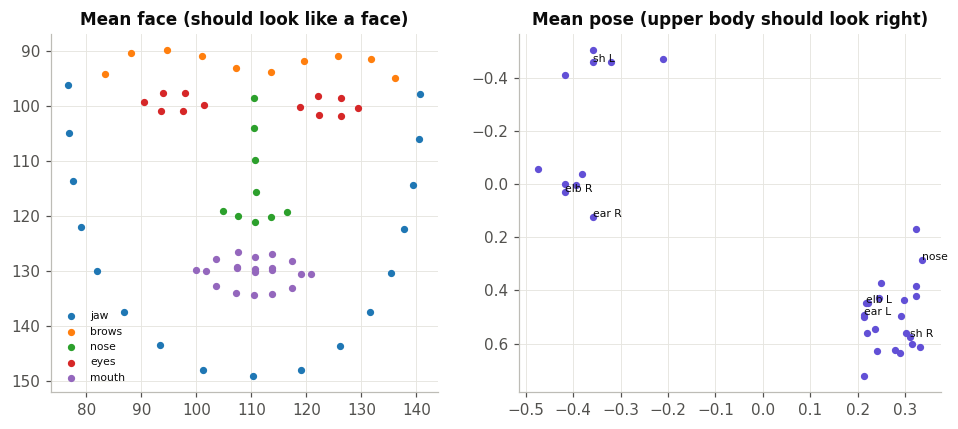

In [ ]:
_ID = {"FL_LAYOUT_USED": None}
EPS = 1e-6

def _names_to_index(cols, axes, n_pts):
    """If columns are named like x_12 / 12_x, return {axis: [col index per landmark]}; else None."""
    idx = {a: {} for a in axes}
    p1 = re.compile(r"^\s*([%s])[\W_]*(\d+)\s*$" % axes, re.I)
    p2 = re.compile(r"^\s*(\d+)[\W_]*([%s])\s*$" % axes, re.I)
    for j, c in enumerate(cols):
        m = p1.match(c)
        if m: a, k = m.group(1).lower(), int(m.group(2))
        else:
            m = p2.match(c)
            if not m: return None
            k, a = int(m.group(1)), m.group(2).lower()
        idx[a][k] = j
    ks = sorted(idx[axes[0]])
    if len(ks) != n_pts or any(sorted(idx[a]) != ks for a in axes): return None
    return {a: [idx[a][k] for k in ks] for a in axes}

def detect_fl_layout(vals):
    s = vals[:: max(1, len(vals) // 3000)]
    s = s[np.isfinite(s).all(1) & (np.abs(s).sum(1) > 0)]
    med = np.median(s, axis=0)
    mono = lambda v: max((np.diff(v) > 0).mean(), (np.diff(v) < 0).mean())
    a, b = mono(med[0:34:2]), mono(med[0:17])
    return ("interleaved" if a >= b else "blocked"), a, b

def face_xy(vals, cols, has_header):
    """-> x, y arrays of shape (T, 68)."""
    if has_header:
        idx = _names_to_index(cols, "xy", 68)
        if idx:
            _ID["FL_LAYOUT_USED"] = "from column names"
            return vals[:, idx["x"]], vals[:, idx["y"]]
    layout = FL_LAYOUT
    if layout == "auto":
        if _ID["FL_LAYOUT_USED"] in ("interleaved", "blocked"):
            layout = _ID["FL_LAYOUT_USED"]
        else:
            layout, a, b = detect_fl_layout(vals)
            print(f"FL layout detected: {layout}  (jaw-monotonic score interleaved={a:.2f}, blocked={b:.2f})")
    _ID["FL_LAYOUT_USED"] = layout
    return (vals[:, 0::2], vals[:, 1::2]) if layout == "interleaved" else (vals[:, :68], vals[:, 68:])

def pose_xyz(vals, cols, has_header):
    """-> array (T, 33, 3)."""
    if has_header:
        idx = _names_to_index(cols, "xyz", 33)
        if idx: return np.stack([vals[:, idx[a]] for a in "xyz"], axis=2)
    if PL_LAYOUT == "axis_major":
        return vals.reshape(len(vals), 3, 33).transpose(0, 2, 1)
    return vals.reshape(len(vals), 33, 3)

# ---- peek at one session ----
key0 = sorted(SESSIONS)[0]
print("Peeking at session", key0)
raw0 = {}
for sig in MODALITIES:
    frame, vals, cols, hh = read_feature_csv(SESSIONS[key0][sig], sig)
    raw0[sig] = (frame, vals, cols, hh)
    print(f"{sig}: {SESSIONS[key0][sig].name} rows={len(frame):,} value columns={vals.shape[1]} header={hh} "
          f"frames {frame.min()}..{frame.max()} = {len(frame)/FPS/60:.1f} min at {FPS} fps, NaN share={np.isnan(vals).mean():.3%}")
    display(pd.DataFrame(vals[:3, :6], columns=cols[:6]))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
if "FL" in raw0:
    fr, v, c, hh = raw0["FL"]
    x, y = face_xy(v, c, hh)
    ok = np.isfinite(x).all(1) & (np.abs(x).sum(1) > 0)
    mx, my = np.nanmean(x[ok], 0), np.nanmean(y[ok], 0)
    regions = [(range(0, 17), "jaw"), (range(17, 27), "brows"), (range(27, 36), "nose"),
               (range(36, 48), "eyes"), (range(48, 68), "mouth")]
    for r, nm in regions:
        axes[0].scatter(mx[list(r)], my[list(r)], s=14, label=nm)
    axes[0].invert_yaxis(); axes[0].set_aspect("equal"); axes[0].legend(fontsize=7, frameon=False)
    axes[0].set_title("Mean face (should look like a face)")
if "PL" in raw0:
    fr, v, c, hh = raw0["PL"]
    P = pose_xyz(v, c, hh); ok = np.isfinite(P).all((1, 2)) & (np.abs(P).sum((1, 2)) > 0)
    mp = P[ok].mean(0)
    axes[1].scatter(mp[:, 0], mp[:, 1], s=14, color="#6250d6")
    for j, nm in {0: "nose", 7: "ear L", 8: "ear R", 11: "sh L", 12: "sh R", 13: "elb L", 14: "elb R"}.items():
        axes[1].annotate(nm, (mp[j, 0], mp[j, 1]), fontsize=7)
    axes[1].invert_yaxis(); axes[1].set_title("Mean pose (upper body should look right)")
    # advisory: under axis_major the first two columns are x of two neighbouring joints (very correlated)
    r01 = abs(np.corrcoef(v[ok, 0], v[ok, 1])[0, 1])
    print(f"PL advisory: |corr(col0, col1)| = {r01:.2f}  (high ~0.9+ suggests 'axis_major'; low suggests 'point_major'); using {PL_LAYOUT}")
plt.tight_layout(); plt.show()

## 4. Per-frame signals

Raw landmark columns are not useful directly (they change with camera distance and head position). I convert them to dimensionless signals that mean something physically:

* **EAR** (eye aspect ratio): how open the eye is. **MAR**: how open the mouth is (yawns).
* **Head pose proxies**: yaw, pitch, roll, from landmark geometry.
* **Brow gap, mouth width**, and the **30 facial action units** (FAU, including blink) as they are.
* **Pose (PL)**: shoulder position and width, head position relative to the shoulders (slouching, nodding forward).

In [ ]:
def face_signals(x, y):
    d = lambda i, j: np.hypot(x[:, i] - x[:, j], y[:, i] - y[:, j])
    iod = d(36, 45)                                                    # outer-eye-corner distance (scale)
    ear_r = (d(37, 41) + d(38, 40)) / (2 * d(36, 39) + EPS)
    ear_l = (d(43, 47) + d(44, 46)) / (2 * d(42, 45) + EPS)
    mar = (d(61, 67) + d(62, 66) + d(63, 65)) / (3 * d(60, 64) + EPS)
    face_w = d(0, 16)
    yaw = ((x[:, 30] - x[:, 0]) - (x[:, 16] - x[:, 30])) / (face_w + EPS)      # nose off-centre between jaw edges
    eye_y = (y[:, 36] + y[:, 45]) / 2
    pitch = (y[:, 30] - eye_y) / (np.abs(y[:, 8] - eye_y) + EPS)               # nose drop relative to eye-chin span
    roll = np.arctan2(y[:, 45] - y[:, 36], x[:, 45] - x[:, 36])
    out = {"ear_l": ear_l, "ear_r": ear_r, "ear": (ear_l + ear_r) / 2, "mar": mar, "yaw": yaw, "pitch": pitch,
           "roll": roll, "brow_gap": ((d(19, 37) + d(24, 43)) / 2) / (iod + EPS), "mouth_w": d(48, 54) / (iod + EPS)}
    bad = ~np.isfinite(x).all(1) | ~np.isfinite(y).all(1) | (iod < 1e-3) | (np.abs(x).sum(1) == 0)
    return {k: np.where(bad, np.nan, v).astype(np.float32) for k, v in out.items()}

def pose_signals(P):
    nose, ear_l, ear_r, sh_l, sh_r = P[:, 0], P[:, 7], P[:, 8], P[:, 11], P[:, 12]
    sh_mid, ear_mid = (sh_l + sh_r) / 2, (ear_l + ear_r) / 2
    out = {"sh_mid_x": sh_mid[:, 0], "sh_mid_y": sh_mid[:, 1],
           "sh_width": np.hypot(sh_l[:, 0] - sh_r[:, 0], sh_l[:, 1] - sh_r[:, 1]),
           "sh_tilt": np.arctan2(sh_r[:, 1] - sh_l[:, 1], sh_r[:, 0] - sh_l[:, 0]),
           "ear_tilt": np.arctan2(ear_r[:, 1] - ear_l[:, 1], ear_r[:, 0] - ear_l[:, 0]),
           "nose_rel_x": nose[:, 0] - sh_mid[:, 0], "nose_rel_y": nose[:, 1] - sh_mid[:, 1],
           "ear_rel_x": ear_mid[:, 0] - sh_mid[:, 0], "ear_rel_y": ear_mid[:, 1] - sh_mid[:, 1],
           "nose_z": nose[:, 2] - sh_mid[:, 2]}
    bad = ~np.isfinite(P).all((1, 2)) | (np.abs(P).sum((1, 2)) == 0)
    return {k: np.where(bad, np.nan, v).astype(np.float32) for k, v in out.items()}

def au_signals(vals, cols):
    out, seen = {}, set()
    for j, c in enumerate(cols):
        name = re.sub(r"\W+", "_", c).strip("_") or f"au{j}"
        while name in seen: name += "_"
        seen.add(name); out[name] = vals[:, j]
    return out

## 5. Cleaning and per-subject normalisation

For each subject (both sessions together):

1. Build the per-frame signal table for each session and align the three files on frame number.
2. Compute **eye-closed** and **mouth-open** flags from the *raw* EAR / MAR (needed for PERCLOS, blinks and yawns).
3. Interpolate short gaps (up to 0.5 s). Longer gaps stay missing and make a window invalid.
4. **Normalise per subject** with median and robust spread, so that differences between faces and cameras do not swamp the drowsiness signal. This uses only the subject's own unlabeled features, but it needs a calibration period in a real car (see the doc).
5. Clip extreme values to +/- 6 robust standard deviations.

In [ ]:
BINARY = ["FL_closed", "FL_mopen"]

def load_session_signals(subj, st):
    paths = SESSIONS[(subj, st)]
    parts = []
    if "FL" in MODALITIES:
        frame, vals, cols, hh = read_feature_csv(paths["FL"], "FL")
        x, y = face_xy(vals, cols, hh)
        parts.append(pd.DataFrame({f"FL_{k}": v for k, v in face_signals(x, y).items()}, index=frame))
    if "FAU" in MODALITIES:
        frame, vals, cols, hh = read_feature_csv(paths["FAU"], "FAU")
        parts.append(pd.DataFrame({f"FAU_{k}": v for k, v in au_signals(vals, cols).items()}, index=frame))
    if "PL" in MODALITIES:
        frame, vals, cols, hh = read_feature_csv(paths["PL"], "PL")
        parts.append(pd.DataFrame({f"PL_{k}": v for k, v in pose_signals(pose_xyz(vals, cols, hh)).items()}, index=frame))
    parts = [p[~p.index.duplicated()] for p in parts]
    df = pd.concat(parts, axis=1, join="outer").sort_index()
    off = int(df.index.min()) if df.index.min() in (0, 1) else 0       # frame numbering starts at 0 or 1
    df.index = df.index - off
    df = df.reindex(np.arange(0, int(df.index.max()) + 1)).astype(np.float32)   # missing frames become NaN rows
    return df.iloc[: N_INTERVALS * INTERVAL_FRAMES]

def prepare_subject(subj):
    """-> {state: (clean+normalised DataFrame, ok mask)} for one subject."""
    sess = {st: load_session_signals(subj, st) for st in ("A", "D") if (subj, st) in SESSIONS}
    if "FL" in MODALITIES:                                              # flags from RAW signals
        ear_med = np.nanmedian(np.concatenate([d["FL_ear"].values for d in sess.values()]))
        for d in sess.values():
            d["FL_closed"] = (d["FL_ear"] < EAR_CLOSE_FRAC * ear_med).astype(np.float32).where(d["FL_ear"].notna())
            d["FL_mopen"] = (d["FL_mar"] > MAR_OPEN_THR).astype(np.float32).where(d["FL_mar"].notna())
    ok = {st: d.notna().all(axis=1).values for st, d in sess.items()}   # frame fully observed before repair
    for st in sess:
        sess[st] = sess[st].interpolate(limit=INTERP_LIMIT, limit_direction="both")
    cont = [c for c in next(iter(sess.values())).columns if c not in BINARY]
    def robust(frame):
        med = frame.median()
        spread = ((frame - med).abs().median() * 1.4826).where(lambda s: s > 1e-6, frame.std())
        return med, spread.where(spread > 1e-6, 1.0)
    if SUBJECT_NORM == "subject":
        med, spread = robust(pd.concat(w[d[cont] for d in sess.values()]))
    for st, d in sess.items():
        if SUBJECT_NORM == "session": med, spread = robust(d[cont])
        if SUBJECT_NORM != "none":
            d[cont] = ((d[cont] - med) / spread).clip(-6, 6)
        sess[st] = d.fillna(0.0)
    return {st: (sess[st], ok[st]) for st in sess}

## 6. Windows, labels, feature tables and cache

Each session is cut into 10-second windows with 50% overlap. A window gets the KSS of the 4-minute interval it lies in; windows that straddle two intervals are dropped (their label would be ambiguous). For every window two representations are built:

* **Tabular features** for ML and ANN: mean, std, min, max and slope of each continuous signal, the fraction of frames for each flag, plus event features: PERCLOS, blink count and duration, longest eye closure, long closures (>= 0.5 s) and yawn count.
* **Sequence tensor** for CNN / RNN / LSTM / GRU / Transformer: the signals averaged down to 10 steps per second, so a window is 100 steps x features.

In [ ]:
def run_lengths(b):
    b = np.concatenate(([0], b.astype(np.int8), [0]))
    d = np.diff(b)
    return np.flatnonzero(d == -1) - np.flatnonzero(d == 1)

BLINK_MIN = max(1, round(0.05 * FPS)); BLINK_MAX = max(2, round(0.5 * FPS)); YAWN_MIN = max(2, round(YAWN_MIN_SEC * FPS))
EVENT_NAMES = ["FL_blink_count", "FL_blink_dur_s", "FL_closure_max_s", "FL_long_closures", "FL_yawn_count"]

def event_features(closed, mopen):
    out = np.zeros((len(closed), len(EVENT_NAMES)), np.float32)
    for i in range(len(closed)):
        r = run_lengths(closed[i] > 0.5)
        blinks = r[(r >= BLINK_MIN) & (r < BLINK_MAX)]
        out[i, 0] = len(blinks)
        out[i, 1] = blinks.mean() / FPS if len(blinks) else 0.0
        out[i, 2] = r.max() / FPS if len(r) else 0.0
        out[i, 3] = (r >= BLINK_MAX).sum()
        out[i, 4] = (run_lengths(mopen[i] > 0.5) >= YAWN_MIN).sum()
    return out

def make_windows(df, ok, kss_row, subj, st):
    cols = list(df.columns)
    Z = df.to_numpy(np.float32)
    T = len(Z)
    starts = np.arange(0, T - WIN + 1, STRIDE)
    a, b = starts // INTERVAL_FRAMES, (starts + WIN - 1) // INTERVAL_FRAMES
    keep = (a == b) & (a < len(kss_row))                     # drop windows that straddle two KSS intervals
    starts, a = starts[keep], a[keep]
    ok_frac = np.array([ok[s:s + WIN].mean() for s in starts])
    keep = ok_frac >= MIN_OK_FRAC
    starts, a, ok_frac = starts[keep], a[keep], ok_frac[keep]
    if len(starts) == 0: return None
    Zw = Z[starts[:, None] + np.arange(WIN)[None, :]]       # (n, WIN, F)
    cont_i = [i for i, c in enumerate(cols) if c not in BINARY]
    bin_i = [i for i, c in enumerate(cols) if c in BINARY]
    Zc = Zw[:, :, cont_i]
    t = np.arange(WIN, dtype=np.float32); t -= t.mean()
    feats = [Zc.mean(1), Zc.std(1), Zc.min(1), Zc.max(1), (Zc * t[None, :, None]).sum(1) / (t ** 2).sum()]
    names = [f"{cols[i]}__{s}" for s in ("mean", "std", "min", "max", "slope") for i in cont_i]
    if bin_i:
        feats.append(Zw[:, :, bin_i].mean(1)); names += [f"{cols[i]}__frac" for i in bin_i]
        feats.append(event_features(Zw[:, :, cols.index("FL_closed")], Zw[:, :, cols.index("FL_mopen")])); names += EVENT_NAMES
    X_tab = np.concatenate(feats, axis=1).astype(np.float32)
    X_seq = Zw.reshape(len(Zw), L_STEPS, DS, Zw.shape[2]).mean(2).astype(np.float32)
    kss = np.asarray(kss_row, float)[a]
    n = len(starts)
    return dict(X_tab=X_tab, X_seq=X_seq, kss=kss.astype(np.float32), y=kss_to_class(kss).astype(np.int8),
                subj=np.array([subj] * n), state=np.array([st] * n), interval=a.astype(np.int8),
                t_sec=(starts / FPS).astype(np.float32), ok_frac=ok_frac.astype(np.float32)), names, cols

CFG_TAG = hashlib.md5(json.dumps([FPS, WIN, STRIDE, SEQ_HZ, MODALITIES, LABEL_MODE, KSS_LOW_BELOW, KSS_HIGH_FROM,
        SUBJECT_NORM, EAR_CLOSE_FRAC, MAR_OPEN_THR, YAWN_MIN_SEC, INTERVAL_MIN, N_INTERVALS, MIN_OK_FRAC,
        FL_LAYOUT, PL_LAYOUT, sorted(SUBJECTS)]).encode()).hexdigest()[:8]
NAMES_JSON = CACHE_DIR / f"names_{CFG_TAG}.json"

def build_cache(force=False):
    t0 = time.time()
    for subj in SUBJECTS:
        f = CACHE_DIR / f"win_{CFG_TAG}_{subj}.npz"
        if f.exists() and not force: continue
        sess = prepare_subject(subj)
        recs = []
        for st, (df, ok) in sess.items():
            res = make_windows(df, ok, LABELS[(subj, st)], subj, st)
            if res is None: print(f"  {subj}_{st}: no valid windows"); continue
            rec, tab_names, seq_names = res
            recs.append(rec)
        if recs:
            np.savez_compressed(f, **{k: np.concatenate([r[k] for r in recs]) for k in recs[0]})
            NAMES_JSON.write_text(json.dumps({"tab": tab_names, "seq": seq_names}))
        print(f"  subject {subj}: {sum(len(r['y']) for r in recs)} windows  ({time.time()-t0:.0f}s elapsed)")

build_cache()

def load_windows():
    parts = [np.load(CACHE_DIR / f"win_{CFG_TAG}_{s}.npz") for s in SUBJECTS if (CACHE_DIR / f"win_{CFG_TAG}_{s}.npz").exists()]
    D = {k: np.concatenate([p[k] for p in parts]) for k in parts[0].files}
    nm = json.loads(NAMES_JSON.read_text())
    return D, nm["tab"], nm["seq"]

D, TAB_NAMES, SEQ_NAMES = load_windows()
X_tab, X_seq, y, groups = D["X_tab"], D["X_seq"], D["y"].astype(int), D["subj"]
TAB_GROUPS = np.array([n.split("_")[0] for n in TAB_NAMES])      # FL / FAU / PL, used for the modality ablation
SEQ_GROUPS = np.array([n.split("_")[0] for n in SEQ_NAMES])
print(f"\n{len(y):,} windows from {len(set(groups))} subjects | tabular {X_tab.shape} | sequence {X_seq.shape}")
print("window class counts:", {c: int(n) for c, n in zip(CLASS_NAMES, np.bincount(y, minlength=K))})
assert np.isfinite(X_tab).all() and np.isfinite(X_seq).all(), "NaN/inf survived cleaning"

  subject A: 889 windows  (24s elapsed)
  subject B: 937 windows  (57s elapsed)
  subject C: 462 windows  (73s elapsed)
  subject D: 927 windows  (107s elapsed)
  subject E: 799 windows  (140s elapsed)
  subject F: 468 windows  (156s elapsed)
  subject G: 940 windows  (190s elapsed)
  subject H: 938 windows  (223s elapsed)
  subject I: 940 windows  (255s elapsed)
  subject J: 933 windows  (289s elapsed)
  subject K: 936 windows  (320s elapsed)
  subject L: 470 windows  (338s elapsed)
  subject M: 938 windows  (371s elapsed)
  subject N: 932 windows  (401s elapsed)
  subject O: 779 windows  (435s elapsed)
  subject P: 934 windows  (468s elapsed)
  subject Q: 928 windows  (501s elapsed)
  subject R: 934 windows  (535s elapsed)
  subject S: 929 windows  (568s elapsed)

16,013 windows from 19 subjects | tabular (16013, 252) | sequence (16013, 100, 51)
window class counts: {'Low': 6233, 'Medium': 3964, 'High': 5816}


## 7. Exploratory data analysis

The EDA answers four questions: (1) how are the labels distributed and how do they change over a session, (2) is there missing data, (3) which features separate the classes, (4) how strong is the *subject* effect compared with the *class* effect. The last one decides how carefully the data must be split.

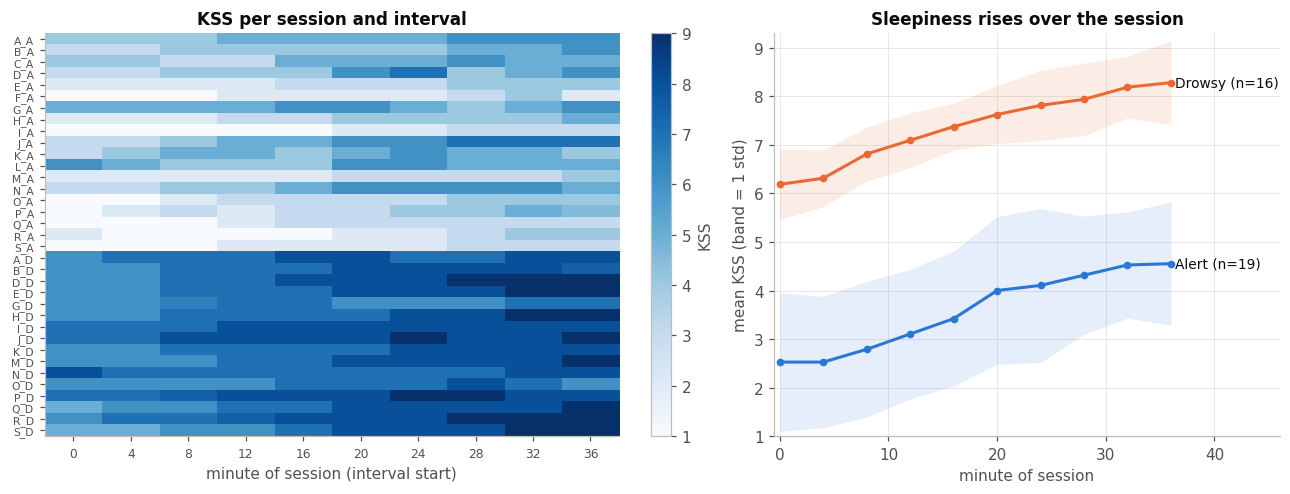

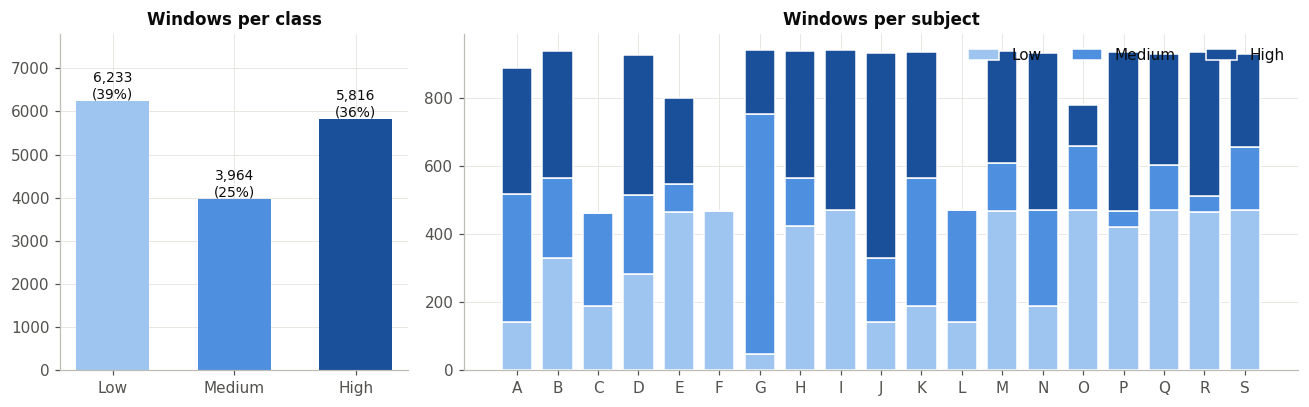

Share of frames missing before repair, per window: median 0.00%, 95th percentile 1.17%


In [ ]:
cls_name = np.array(CLASS_NAMES)[y]
tab = pd.DataFrame(X_tab, columns=TAB_NAMES)
tab["class"] = pd.Categorical(cls_name, categories=CLASS_NAMES, ordered=True)

# ---- 7.1 labels: heatmap of KSS per session and interval, mean trajectory by session type ----
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})
keys = sorted(SESSIONS, key=lambda k: (k[1], k[0]))
M = np.array([LABELS[k] for k in keys])
im = ax[0].imshow(M, aspect="auto", cmap="Blues", vmin=1, vmax=9)
ax[0].set_yticks(range(len(keys))); ax[0].set_yticklabels([f"{s}_{SESSION_NAME[t][0]}" for s, t in keys], fontsize=7)
ax[0].set_xticks(range(N_INTERVALS)); ax[0].set_xticklabels([f"{i*INTERVAL_MIN:g}" for i in range(N_INTERVALS)], fontsize=8)
ax[0].set_xlabel("minute of session (interval start)"); ax[0].set_title("KSS per session and interval"); ax[0].grid(False)
plt.colorbar(im, ax=ax[0], fraction=0.04, label="KSS")
for st, col in (("A", "#2a78d6"), ("D", "#eb6834")):
    arr = np.array([LABELS[k] for k in LABELS if k[1] == st and k in SESSIONS])
    if len(arr):
        xs = np.arange(N_INTERVALS) * INTERVAL_MIN
        ax[1].plot(xs, arr.mean(0), color=col, lw=2, marker="o", ms=4)
        ax[1].fill_between(xs, arr.mean(0) - arr.std(0), arr.mean(0) + arr.std(0), color=col, alpha=0.12, lw=0)
        ax[1].text(xs[-1] + 0.4, arr.mean(0)[-1], f"{SESSION_NAME[st]} (n={len(arr)})", color=INK, va="center", fontsize=9)
ax[1].set_xlim(-0.5, N_INTERVALS * INTERVAL_MIN + 6); ax[1].set_ylim(1, 9.3)
ax[1].set_xlabel("minute of session"); ax[1].set_ylabel("mean KSS (band = 1 std)"); ax[1].set_title("Sleepiness rises over the session")
plt.tight_layout(); plt.show()

# ---- 7.2 window class balance overall and per subject ----
ct = pd.crosstab(groups, cls_name).reindex(columns=CLASS_NAMES, fill_value=0)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 2.4]})
tot = ct.sum()
ax[0].bar(CLASS_NAMES, tot.values, color=CLASS_COLORS, width=0.6)
for i, v in enumerate(tot.values): ax[0].text(i, v, f"{v:,}\n({v/tot.sum():.0%})", ha="center", va="bottom", fontsize=9)
ax[0].set_ylim(0, tot.max() * 1.25); ax[0].set_title("Windows per class")
bottom = np.zeros(len(ct))
for c, col in zip(CLASS_NAMES, CLASS_COLORS):
    ax[1].bar(ct.index, ct[c].values, bottom=bottom, color=col, width=0.75, edgecolor="white", linewidth=1, label=c); bottom += ct[c].values
ax[1].legend(frameon=False, ncol=K, loc="upper right"); ax[1].set_title("Windows per subject")
plt.tight_layout(); plt.show()

# ---- 7.3 data quality ----
print(f"Share of frames missing before repair, per window: median {1-np.median(D['ok_frac']):.2%}, "
      f"95th percentile {1-np.percentile(D['ok_frac'], 5):.2%}")

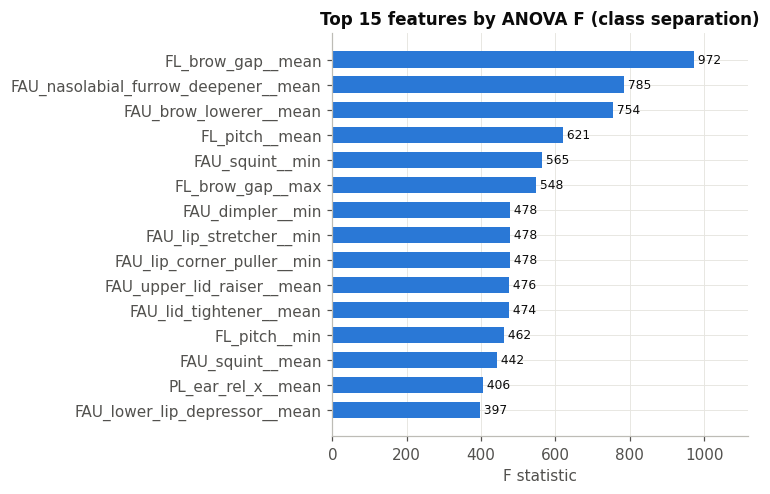

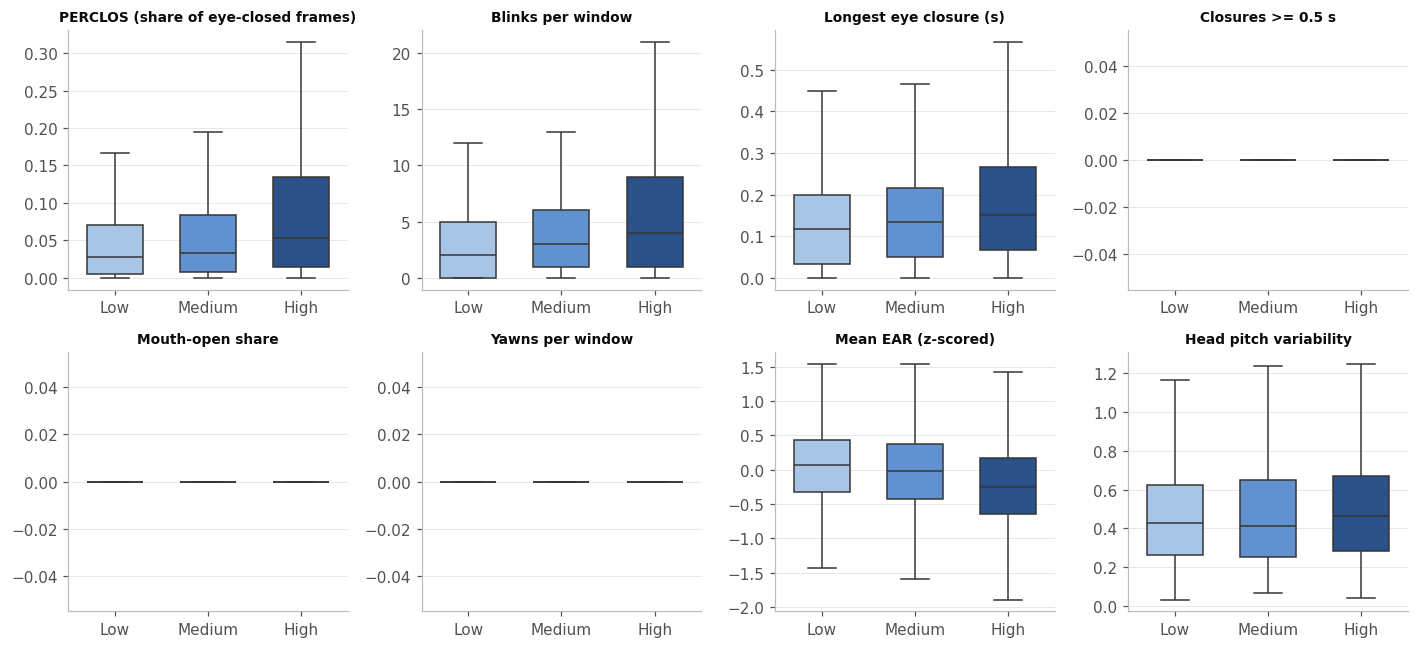

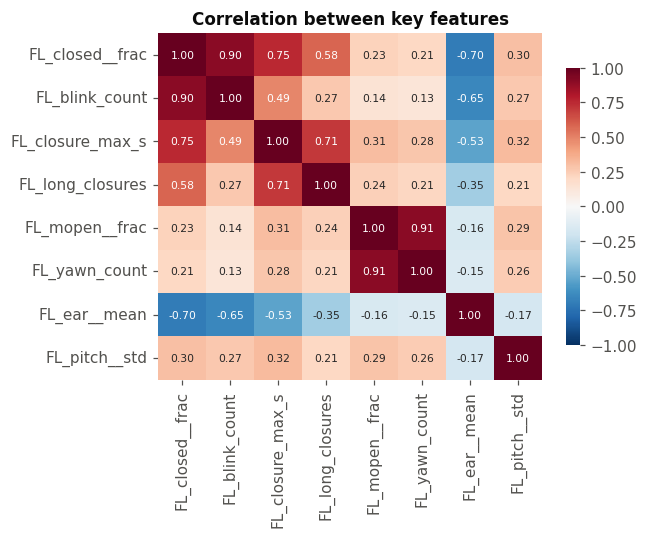

In [ ]:
# ---- 7.4 which features separate the classes? ----
from sklearn.feature_selection import f_classif
F, _ = f_classif(np.nan_to_num(X_tab), y)
top = pd.Series(F, index=TAB_NAMES).sort_values(ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(top.index, top.values, color="#2a78d6", height=0.65)
for i, v in enumerate(top.values): ax.text(v, i, f" {v:,.0f}", va="center", fontsize=8)
ax.set_title("Top 15 features by ANOVA F (class separation)"); ax.set_xlabel("F statistic")
ax.set_xlim(0, top.max() * 1.15); plt.tight_layout(); plt.show()

# ---- 7.5 distributions of the interpretable drowsiness features by class ----
want = [("FL_closed__frac", "PERCLOS (share of eye-closed frames)"), ("FL_blink_count", "Blinks per window"),
        ("FL_closure_max_s", "Longest eye closure (s)"), ("FL_long_closures", "Closures >= 0.5 s"),
        ("FL_mopen__frac", "Mouth-open share"), ("FL_yawn_count", "Yawns per window"),
        ("FL_ear__mean", "Mean EAR (z-scored)"), ("FL_pitch__std", "Head pitch variability")]
want = [(c, t) for c, t in want if c in tab.columns]
if want:
    fig, axes = plt.subplots(2, (len(want) + 1) // 2, figsize=(13, 6)); axes = np.atleast_1d(axes).ravel()
    for a, (c, t) in zip(axes, want):
        sns.boxplot(data=tab, x="class", y=c, palette=CLASS_COLORS, ax=a, showfliers=False, linewidth=1, width=0.6)
        a.set_title(t, fontsize=9); a.set_xlabel(""); a.set_ylabel("")
    for a in axes[len(want):]: a.axis("off")
    plt.tight_layout(); plt.show()

# ---- 7.6 correlation among the interpretable features ----
cc = [c for c, _ in want]
if len(cc) > 2:
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(tab[cc].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax,
                annot_kws={"size": 7}, cbar_kws={"shrink": .8}); ax.set_title("Correlation between key features"); plt.tight_layout(); plt.show()

## 8. Evaluation protocol: subject-wise cross-validation

Neighbouring windows of one person look almost identical and share a label. With a random split the model sees the same person in train and test and the score is inflated. So **all folds are split by subject**: `StratifiedGroupKFold` keeps every subject entirely in one fold while balancing the classes. The folds are fixed once (seed 42) and **reused by every model, including the image models**, so the comparison is fair. Scalers are always fit on the training part only.

Metrics: accuracy, balanced accuracy, **macro-F1** (main metric, because classes are unequal), recall of the most drowsy class, and one-vs-rest AUC.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score,
                             roc_auc_score, confusion_matrix)
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight

sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
FOLDS = list(sgkf.split(X_tab, y, groups))
FOLD_OF_SUBJECT = {s: f for f, (_, te) in enumerate(FOLDS) for s in np.unique(groups[te])}
for tr, te in FOLDS:
    assert not (set(groups[tr]) & set(groups[te])), "subject leakage between train and test!"
rows = []
for f, (tr, te) in enumerate(FOLDS):
    rows.append({"fold": f, "test subjects": " ".join(sorted(set(groups[te]))), "train windows": len(tr), "test windows": len(te),
                 **{f"test {c}": int((y[te] == i).sum()) for i, c in enumerate(CLASS_NAMES)}})
display(pd.DataFrame(rows).set_index("fold"))

RESULTS, ABLATION, OOF, HIST = [], [], {}, {}

def compute_metrics(y_true, prob):
    pred = prob.argmax(1)
    m = {"accuracy": accuracy_score(y_true, pred), "bal_acc": balanced_accuracy_score(y_true, pred),
         "macro_f1": f1_score(y_true, pred, average="macro", labels=range(K), zero_division=0),
         "recall_top": recall_score(y_true, pred, labels=[K - 1], average="macro", zero_division=0)}
    try:
        if K > 2:
            m["auc"] = roc_auc_score(y_true, prob, multi_class="ovr", average="macro", labels=list(range(K)))
        else:
            m["auc"] = roc_auc_score(y_true, prob[:, 1])
    except ValueError:
        m["auc"] = np.nan
    return m

def log_result(model, family, dataset, fold, seed, y_true, prob, n_params, train_s, infer_ms, test_idx, bucket=None):
    bucket = RESULTS if bucket is None else bucket
    bucket.append(dict(model=model, family=family, dataset=dataset, fold=fold, seed=seed, **compute_metrics(y_true, prob),
                       params=n_params, train_s=train_s, infer_ms=infer_ms))
    if bucket is RESULTS and seed == SEEDS[0]:
        OOF.setdefault(model, {})[fold] = (test_idx, y_true, prob.argmax(1))

def to_proba(model, X):
    if hasattr(model, "predict_proba"): return model.predict_proba(X)
    s = model.decision_function(X)
    if s.ndim == 1: s = np.stack([-s, s], 1)
    e = np.exp(s - s.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

def summarize(df):
    g = df.groupby("model")
    out = g[["accuracy", "bal_acc", "macro_f1", "recall_top", "auc"]].mean()
    out["macro_f1_std"] = g["macro_f1"].std()
    for c in ("params", "train_s", "infer_ms"): out[c] = g[c].mean()
    out["family"] = g["family"].first(); out["dataset"] = g["dataset"].first()
    return out.sort_values("macro_f1", ascending=False)

from sklearn.metrics import classification_report

def explain_fold0(label, y_true, prob, hist=None):
    """The three things to look at for one model on fold 0: classification report, confusion matrix, learning curves."""
    pred = prob.argmax(1)
    print(f"\nFold-0 classification report: {label}")
    print(classification_report(y_true, pred, labels=list(range(K)), target_names=CLASS_NAMES, zero_division=0, digits=3))
    n = 3 if hist is not None else 1
    fig, axes = plt.subplots(1, n, figsize=(4.4 * n, 3.4))
    axes = np.atleast_1d(axes)
    cm = confusion_matrix(y_true, pred, labels=list(range(K)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0], xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    axes[0].set_xlabel("predicted"); axes[0].set_ylabel("true"); axes[0].set_title("Confusion matrix (fold 0)", fontsize=9)
    if hist is not None:
        for a, key, title in ((axes[1], "loss", "Loss"), (axes[2], "accuracy", "Accuracy")):
            a.plot(hist[key], color="#2a78d6", lw=1.6); a.plot(hist["val_" + key], color="#eb6834", lw=1.6)
            a.text(len(hist[key]) - 1, hist[key][-1], " train", color=INK, fontsize=8, va="center")
            a.text(len(hist[key]) - 1, hist["val_" + key][-1], " val", color=INK, fontsize=8, va="center")
            a.set_title(f"{title} per epoch", fontsize=9); a.set_xlabel("epoch")
    fig.suptitle(label, fontsize=10); plt.tight_layout(); plt.show()

,test subjects,train windows,test windows,test Low,test Medium,test High
fold,,,,,,
0,C E G P,12878,3135,1120,1108,907
1,B H O R,12425,3588,1686,612,1290
2,J Q S,13223,2790,1081,507,1202
3,D L M N,12746,3267,1079,985,1203
4,A F I K,12780,3233,1267,752,1214


## 9. Classical machine learning (the baselines)

**Idea of this stage:** before any neural network, see how far simple models get on the *window feature table* (about 250 numbers per 10-second window: eye, mouth and head statistics, PERCLOS, blink and yawn counts). Each model gets its own cell, and for each one you will see the result and, for fold 0, a classification report and a confusion matrix.

**How to read a result line:** *macro-F1* is the main score (average F1 of the three classes, so the large class cannot hide a bad small class). *acc* is plain accuracy. The `+/-` is the spread across the 5 test folds, i.e. how much the score changes when different people are held out.

The order is from the simplest to the strongest tabular model: majority class (the floor) → Logistic Regression → SVM → Random Forest → gradient boosting.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except ImportError:
    HAVE_XGB = False

RF_IMPORTANCE = []

def run_sklearn(name, factory, needs_sw, X=None, bucket=None, label=None, family="ML", explain=False):
    X = X_tab if X is None else X
    t_all = time.time()
    for fold, (tr, te) in enumerate(FOLDS):
        sc = StandardScaler().fit(X[tr])
        Xtr, Xte = sc.transform(X[tr]), sc.transform(X[te])
        m = factory()
        t0 = time.time()
        m.fit(Xtr, y[tr], sample_weight=compute_sample_weight("balanced", y[tr])) if needs_sw else m.fit(Xtr, y[tr])
        train_s = time.time() - t0
        t0 = time.time(); prob = to_proba(m, Xte); infer_ms = (time.time() - t0) / len(te) * 1000
        log_result(label or name, family, "windows", fold, 0, y[te], prob, np.nan, train_s, infer_ms, te, bucket)
        if name == "Random Forest" and bucket is None: RF_IMPORTANCE.append(m.feature_importances_)
        if explain and fold == 0: explain_fold0(label or name, y[te], prob)
    df = pd.DataFrame(RESULTS if bucket is None else bucket); df = df[df.model == (label or name)]
    print(f"{(label or name):24s} macro-F1 {df.macro_f1.mean():.3f} +/- {df.macro_f1.std():.3f} | acc {df.accuracy.mean() * 100:.1f}% | {time.time()-t_all:.0f}s")

def make_boosting():
    if HAVE_XGB:
        return XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                             tree_method="hist", eval_metric="mlogloss", n_jobs=-1, random_state=0)
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, max_depth=6, class_weight="balanced", random_state=0)

ML_MODELS = {
    "Majority class (reference)": (lambda: DummyClassifier(strategy="prior"), False),
    "Logistic Regression": (lambda: LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0), False),
    "SVM (RBF, C=1)":      (lambda: SVC(kernel="rbf", C=1.0, class_weight="balanced"), False),
    "SVM (paper config)":  (lambda: SVC(kernel="rbf", C=0.1, class_weight="balanced"), False),
    "Random Forest":       (lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample", n_jobs=-1, random_state=0), False),
    "RF (paper config)":   (lambda: RandomForestClassifier(n_estimators=100, max_depth=5, min_samples_leaf=10, class_weight="balanced", n_jobs=-1, random_state=0), False),
    ("XGBoost" if HAVE_XGB else "HistGradientBoosting"): (make_boosting, HAVE_XGB),
}
print("Baselines ready:", list(ML_MODELS))

Baselines ready: ['Majority class (reference)', 'Logistic Regression', 'SVM (RBF, C=1)', 'SVM (paper config)', 'Random Forest', 'RF (paper config)', 'XGBoost']


### 9.1 Majority-class reference

**Objective:** a "model" that ignores the input and always predicts the most frequent class. It is not a real model, it is the **floor**. Any real model must beat it, otherwise it has learned nothing.

**What to look for:** accuracy will look deceptively decent (because one class is bigger), but macro-F1 will be low, because the other classes are never predicted. This is exactly why macro-F1 is our main metric.


Fold-0 classification report: Majority class (reference)
              precision    recall  f1-score   support

         Low      0.357     1.000     0.526      1120
      Medium      0.000     0.000     0.000      1108
        High      0.000     0.000     0.000       907

    accuracy                          0.357      3135
   macro avg      0.119     0.333     0.175      3135
weighted avg      0.128     0.357     0.188      3135



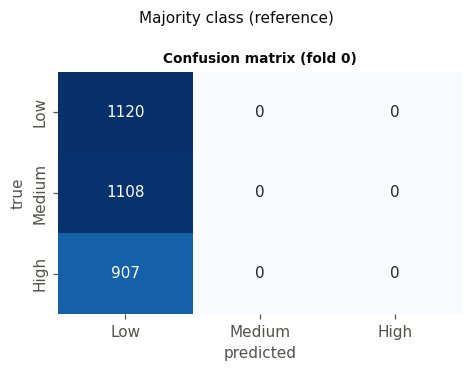

Majority class (reference) macro-F1 0.186 +/- 0.016 | acc 38.7% | 0s


In [ ]:
run_sklearn("Majority class (reference)", *ML_MODELS["Majority class (reference)"], explain=True)

### 9.2 Logistic Regression

**Objective:** the simplest sensible classifier. It draws one straight (linear) boundary between classes using a weighted sum of the features.

**Why first:** it is fast, hard to overfit, and tells us whether the classes are **linearly separable** in our features. If this already works well, the features are good and fancy models have little left to add.

**Settings:** `class_weight="balanced"` makes mistakes on the small classes cost more; features are standardised using the training fold only.

**How to read it:** if Medium is the weakest class in the report, that is expected, because intermediate sleepiness is genuinely fuzzy.


Fold-0 classification report: Logistic Regression
              precision    recall  f1-score   support

         Low      0.292     0.566     0.385      1120
      Medium      0.164     0.068     0.096      1108
        High      0.338     0.189     0.242       907

    accuracy                          0.281      3135
   macro avg      0.265     0.274     0.241      3135
weighted avg      0.260     0.281     0.241      3135



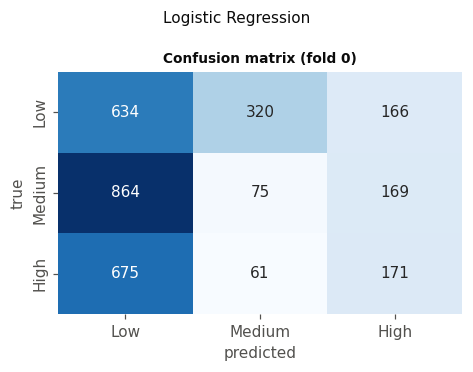

Logistic Regression      macro-F1 0.329 +/- 0.091 | acc 35.3% | 44s


In [ ]:
run_sklearn("Logistic Regression", *ML_MODELS["Logistic Regression"], explain=True)

### 9.3 Support Vector Machine (SVM)

**Objective:** find the boundary with the **widest margin** between classes. With the RBF kernel the boundary can be curved, so it can capture non-linear patterns that logistic regression cannot.

**Why next:** it is the natural step up from a linear model, and it is the baseline used in the dataset paper. We run it twice: `C=1` (our default) and `C=0.1` (the paper's configuration), so our numbers can be compared with the paper's. `C` controls how strictly the model punishes training mistakes: small C = smoother boundary, large C = tighter fit.


Fold-0 classification report: SVM (RBF, C=1)
              precision    recall  f1-score   support

         Low      0.358     0.710     0.476      1120
      Medium      0.093     0.026     0.041      1108
        High      0.371     0.247     0.296       907

    accuracy                          0.334      3135
   macro avg      0.274     0.328     0.271      3135
weighted avg      0.268     0.334     0.270      3135



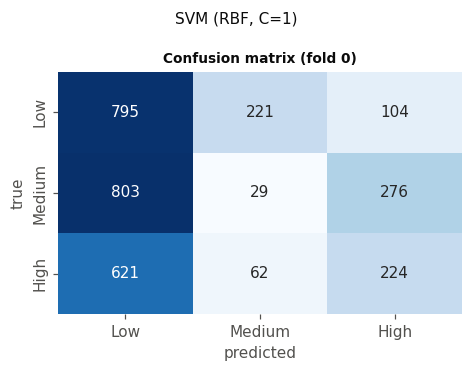

SVM (RBF, C=1)           macro-F1 0.366 +/- 0.082 | acc 39.5% | 98s
SVM (paper config)       macro-F1 0.379 +/- 0.107 | acc 41.2% | 164s


In [ ]:
run_sklearn("SVM (RBF, C=1)", *ML_MODELS["SVM (RBF, C=1)"], explain=True)
#run_sklearn("SVM (paper config)", *ML_MODELS["SVM (paper config)"])

### 9.4 Random Forest

**Objective:** an ensemble of many decision trees, each trained on a random part of the data and features. The final answer is a vote of all trees.

**Why next:** trees capture non-linear rules and **interactions** (for example "eyes closed long AND head nodding") without any feature scaling, and they tell us **which features matter**. The feature-importance chart below is useful for explaining the model in a presentation.




Fold-0 classification report: Random Forest
              precision    recall  f1-score   support

         Low      0.447     0.808     0.576      1120
      Medium      0.081     0.017     0.028      1108
        High      0.839     0.813     0.826       907

    accuracy                          0.530      3135
   macro avg      0.456     0.546     0.477      3135
weighted avg      0.431     0.530     0.455      3135



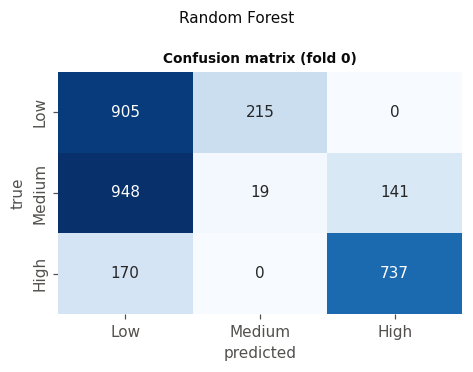

Random Forest            macro-F1 0.480 +/- 0.077 | acc 56.9% | 237s
RF (paper config)        macro-F1 0.461 +/- 0.056 | acc 51.8% | 35s


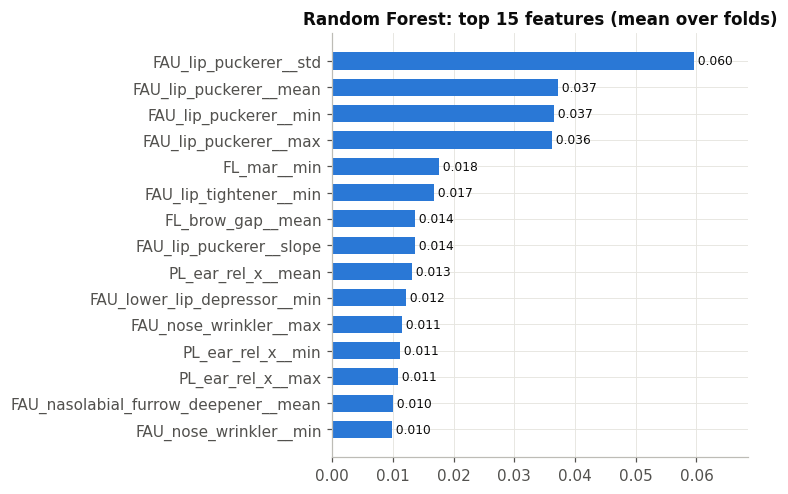

In [ ]:
run_sklearn("Random Forest", *ML_MODELS["Random Forest"], explain=True)
run_sklearn("RF (paper config)", *ML_MODELS["RF (paper config)"])

imp = pd.Series(np.mean(RF_IMPORTANCE, 0), index=TAB_NAMES).sort_values(ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(imp.index, imp.values, color="#2a78d6", height=0.65); ax.set_title("Random Forest: top 15 features (mean over folds)")
for i, v in enumerate(imp.values): ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
ax.set_xlim(0, imp.max() * 1.15); plt.tight_layout(); plt.show()

### 9.5 Gradient boosting (XGBoost)

**Objective:** trees again, but built **one after another**, each new tree correcting the mistakes of the previous ones.

**Why last in this stage:** on tabular data this is usually the strongest classical model, so it is the **bar the neural networks have to beat**. If an LSTM cannot beat this, then the extra complexity is not justified, and that is a valid conclusion for the report.


Fold-0 classification report: XGBoost
              precision    recall  f1-score   support

         Low      0.530     0.729     0.614      1120
      Medium      0.246     0.098     0.141      1108
        High      0.740     0.939     0.828       907

    accuracy                          0.567      3135
   macro avg      0.505     0.589     0.527      3135
weighted avg      0.490     0.567     0.508      3135



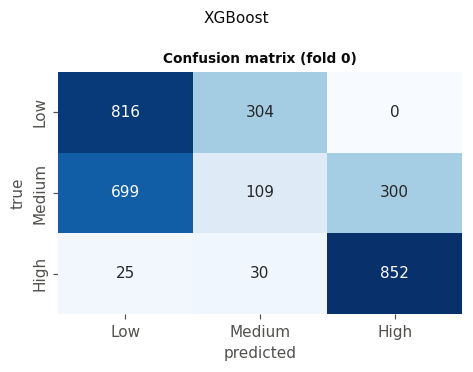

XGBoost                  macro-F1 0.482 +/- 0.067 | acc 54.6% | 168s


In [ ]:
_boost = "XGBoost" if HAVE_XGB else "HistGradientBoosting"
run_sklearn(_boost, *ML_MODELS[_boost], explain=True)

In [ ]:
# ---- stage summary: classical ML ----
_ml = pd.DataFrame(RESULTS)
display(summarize(_ml)[["macro_f1", "macro_f1_std", "accuracy", "bal_acc", "recall_top", "auc"]].round(3))

,macro_f1,macro_f1_std,accuracy,bal_acc,recall_top,auc
model,,,,,,
XGBoost,0.482,0.067,0.546,0.503,0.759,0.664
Random Forest,0.480,0.077,0.569,0.520,0.794,0.711
RF (paper config),0.461,0.056,0.518,0.480,0.715,0.693
SVM (paper config),0.379,0.107,0.412,0.408,0.556,0.572
"SVM (RBF, C=1)",0.366,0.082,0.395,0.388,0.432,0.561
Logistic Regression,0.329,0.091,0.353,0.342,0.391,0.536
Majority class (reference),0.186,0.016,0.387,0.333,0.000,0.500


Random Forest is the best model proven till now using Machine learning.


**Why we now move to neural networks:** the classical models only see my hand-made window statistics. Neural networks can learn their own features, and the sequence models can read the raw time series. The next stage is the simplest neural network, which uses the *same* table, so that the only thing that changes is the model.

## 10. Deep learning helpers and the ANN

All Keras models share one training routine so that differences come from the **architecture**, not the training recipe: Adam optimiser, class weights for imbalance, and **early stopping** on a validation set made of whole subjects held out from the training fold (never from the test fold), with the best weights restored.

**How to read the epoch log** (printed for fold 0 of every model):

| Column | Meaning |
|---|---|
| `accuracy`, `loss` | Performance on the training data. Should improve steadily. |
| `val_accuracy`, `val_loss` | Performance on **held-out subjects**. This is the honest number. |
| gap between them | If train keeps improving while val stalls or gets worse, the model is **overfitting** (memorising the training people). |
| early stopping | Training stops when `val_loss` has not improved for a few epochs, and the best epoch's weights are kept. |

After the log you will see the **architecture table** (`model.summary()`: layers, output shapes, number of parameters), the **learning curves**, a **classification report** and a **confusion matrix** for fold 0. The line at the end of the cell is the result over all 5 folds.

In [ ]:
import tensorflow as tf
tf.get_logger().setLevel("ERROR")
from tensorflow import keras
from tensorflow.keras import layers
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "none (training will be slow)")

def train_keras(name, build_fn, Xtr, ytr, gtr, Xte, yte, te_idx, fold, seed, family, dataset, lr=1e-3, bucket=None, explain=False):
    keras.utils.set_random_seed(seed)
    tr_i, va_i = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=seed).split(Xtr, ytr, gtr))
    classes = np.unique(ytr[tr_i])
    cw = dict(zip(classes, compute_class_weight("balanced", classes=classes, y=ytr[tr_i])))
    model = build_fn(Xtr.shape[1:], K)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    stopper = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    t0 = time.time()
    h = model.fit(Xtr[tr_i], ytr[tr_i], validation_data=(Xtr[va_i], ytr[va_i]), epochs=EPOCHS, batch_size=BATCH,
                  class_weight=cw, verbose=2 if explain else 0, callbacks=[stopper])
    train_s = time.time() - t0
    t0 = time.time(); prob = model.predict(Xte, batch_size=512, verbose=0); infer_ms = (time.time() - t0) / len(Xte) * 1000
    log_result(name, family, dataset, fold, seed, yte, prob, model.count_params(), train_s, infer_ms, te_idx, bucket)
    if fold == 0 and seed == SEEDS[0] and bucket is None: HIST[name] = h.history
    if explain:
        n_ep = len(h.history["loss"]); best = int(np.argmin(h.history["val_loss"])) + 1
        print(f"\nTrained {n_ep} epochs, best epoch {best} (weights restored), {train_s:.0f}s, {model.count_params():,} parameters")
        explain_fold0(name, yte, prob, h.history)
    keras.backend.clear_session()

def standardize_seq(Xtr, Xte):
    mu, sd = Xtr.mean((0, 1), keepdims=True), Xtr.std((0, 1), keepdims=True) + 1e-6
    return (Xtr - mu) / sd, (Xte - mu) / sd

def run_keras(name, build_fn, family, X, kind, lr=1e-3, bucket=None, label=None, explain=False):
    """kind: 'tab' -> StandardScaler, 'seq' -> per-channel standardisation. explain=True shows the details for fold 0."""
    t_all = time.time(); label = label or name
    if explain:
        print(f"===== {label}: architecture =====")
        build_fn(X.shape[1:], K).summary(); keras.backend.clear_session()
        print(f"\n===== {label}: training on fold 0 (epoch log) =====")
    for seed in SEEDS:
        for fold, (tr, te) in enumerate(FOLDS):
            if kind == "tab":
                sc = StandardScaler().fit(X[tr]); Xtr, Xte = sc.transform(X[tr]), sc.transform(X[te])
            else:
                Xtr, Xte = standardize_seq(X[tr], X[te])
            train_keras(label, build_fn, Xtr.astype("float32"), y[tr], groups[tr], Xte.astype("float32"), y[te], te, fold, seed,
                        family, "windows", lr, bucket, explain=(explain and fold == 0 and seed == SEEDS[0]))
    df = pd.DataFrame(RESULTS if bucket is None else bucket); df = df[df.model == label]
    print(f"\n>>> {label:22s} macro-F1 {df.macro_f1.mean():.3f} +/- {df.macro_f1.std():.3f} | acc {df.accuracy.mean():.3f} | "
          f"params {int(df.params.mean()):,} | {time.time()-t_all:.0f}s (all folds)")

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 10.1 ANN (multilayer perceptron)

**Objective:** a neural network made of fully connected (Dense) layers, trained on the **same feature table** as the classical models.

**Why now:** it is the simplest neural network, and it answers one clear question: *does a neural network add anything over classical ML when the input is identical?* Only the model changes, nothing else.

**Architecture:** Dense 256 → 128 → 64, each followed by BatchNorm (stabilises training), ReLU (non-linearity) and Dropout (randomly switches units off to reduce overfitting), then a 3-way softmax that outputs the class probabilities.

**Limit:** it sees one flat row of numbers, so it has no notion of **time order** inside the window. That is the gap the sequence models close.

===== ANN (MLP): architecture =====


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 252)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        64,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 107,907 (421.51 KB)

 Trainable params: 107,011 (418.01 KB)

 Non-trainable params: 896 (3.50 KB)


===== ANN (MLP): training on fold 0 (epoch log) =====
Epoch 1/40
83/83 - 13s - 156ms/step - accuracy: 0.6469 - loss: 0.8196 - val_accuracy: 0.5436 - val_loss: 0.9811
Epoch 2/40
83/83 - 0s - 4ms/step - accuracy: 0.8016 - loss: 0.4912 - val_accuracy: 0.5021 - val_loss: 1.1210
Epoch 3/40
83/83 - 0s - 4ms/step - accuracy: 0.8525 - loss: 0.3804 - val_accuracy: 0.5060 - val_loss: 1.2188
Epoch 4/40
83/83 - 0s - 4ms/step - accuracy: 0.8797 - loss: 0.3156 - val_accuracy: 0.5026 - val_loss: 1.2945
Epoch 5/40
83/83 - 0s - 4ms/step - accuracy: 0.8953 - loss: 0.2813 - val_accuracy: 0.4735 - val_loss: 1.4553
Epoch 6/40
83/83 - 0s - 4ms/step - accuracy: 0.9071 - loss: 0.2471 - val_accuracy: 0.4731 - val_loss: 1.4944
Epoch 7/40
83/83 - 0s - 4ms/step - accuracy: 0.9159 - loss: 0.2252 - val_accuracy: 0.4889 - val_loss: 1.4576

Trained 7 epochs, best epoch 1 (weights restored), 15s, 107,907 parameters

Fold-0 classification report: ANN (MLP)
              precision    recall  f1-score   support

       

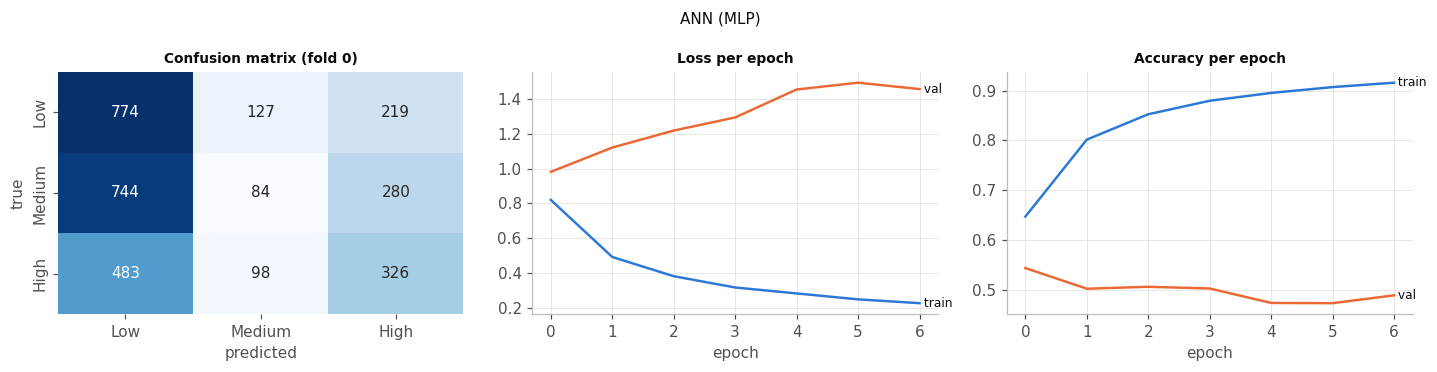


>>> ANN (MLP)              macro-F1 0.355 +/- 0.044 | acc 0.379 | params 107,907 | 80s (all folds)


In [ ]:
def build_ann(input_shape, k):
    inp = keras.Input(input_shape)
    x = inp
    for units, drop in ((256, 0.3), (128, 0.3), (64, 0.2)):
        x = layers.Dense(units)(x); x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x); x = layers.Dropout(drop)(x)
    return keras.Model(inp, layers.Dense(k, activation="softmax")(x))

run_keras("ANN (MLP)", build_ann, "ANN", X_tab, "tab", explain=True)

## 11. Sequence models: CNN, RNN, LSTM, GRU, Transformer, CNN-BiLSTM

**Idea of this stage:** the input is now the window as a **sequence** (100 time steps × about 51 signals), so the model can learn temporal patterns itself instead of relying on my hand-made statistics. The models are ordered by *how they handle time*, from the simplest to the most modern:

| Model | How it handles time | Why it is in the comparison |
|---|---|---|
| 1D-CNN | Sliding filters find short local patterns (a blink, a nod) | Fast, strong baseline for signals |
| Simple RNN | Passes a hidden state step by step | The plain recurrent baseline; weak on long dependencies |
| LSTM | Gated memory cell | Fixes the RNN's vanishing-gradient problem |
| GRU | Simpler gated unit | Similar accuracy to LSTM with fewer parameters |
| Transformer | Self-attention looks at all steps at once | Modern architecture; kept small because data is limited |
| CNN-BiLSTM | CNN finds local patterns, BiLSTM reads them in both directions | The hybrid used in the drowsiness literature |

Every model below has its own cell with: architecture table, epoch log, learning curves, classification report and confusion matrix for fold 0, and its 5-fold result.

In [ ]:
SEQ_MODELS = {}      # filled by the cells below; the ablation section reuses these builders

def head(x, k, units=64, drop=0.3):
    """Shared classifier head: Dropout -> Dense(64) -> softmax. Same for all sequence models, so only the 'body' differs."""
    x = layers.Dropout(drop)(x); x = layers.Dense(units, activation="relu")(x)
    return layers.Dense(k, activation="softmax")(x)
print("Input to every model below:", X_seq.shape[1:], "= (time steps, signals)")

Input to every model below: (100, 51) = (time steps, signals)


### 11.1 1D-CNN

**Objective:** slide small filters along the time axis to detect **short local patterns**, such as a blink, a head nod or a mouth opening.

**Architecture:** 3 Conv1D blocks (64 → 128 → 128 filters) with BatchNorm and ReLU, MaxPooling after the first two (halves the time length, keeps the strongest response), then GlobalAveragePooling (averages over time into one vector) and the shared head.

**Why first:** it is fast and a strong baseline for signal data. It sees *local* patterns but does not model long-range order explicitly.

===== 1D-CNN: architecture =====


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 100, 51)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 100, 64)        │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 100, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 50, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 50, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 50, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 25, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 25, 128)        │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 25, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 25, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 116,483 (455.01 KB)

 Trainable params: 115,843 (452.51 KB)

 Non-trainable params: 640 (2.50 KB)


===== 1D-CNN: training on fold 0 (epoch log) =====
Epoch 1/40
83/83 - 21s - 254ms/step - accuracy: 0.8021 - loss: 0.4957 - val_accuracy: 0.5188 - val_loss: 1.1087
Epoch 2/40
83/83 - 1s - 8ms/step - accuracy: 0.9014 - loss: 0.2540 - val_accuracy: 0.5615 - val_loss: 1.5372
Epoch 3/40
83/83 - 1s - 7ms/step - accuracy: 0.9257 - loss: 0.2044 - val_accuracy: 0.5902 - val_loss: 1.8163
Epoch 4/40
83/83 - 1s - 7ms/step - accuracy: 0.9378 - loss: 0.1611 - val_accuracy: 0.5795 - val_loss: 2.4447
Epoch 5/40
83/83 - 1s - 7ms/step - accuracy: 0.9456 - loss: 0.1471 - val_accuracy: 0.5590 - val_loss: 2.4960
Epoch 6/40
83/83 - 1s - 7ms/step - accuracy: 0.9531 - loss: 0.1284 - val_accuracy: 0.5825 - val_loss: 2.6700
Epoch 7/40
83/83 - 1s - 7ms/step - accuracy: 0.9590 - loss: 0.1120 - val_accuracy: 0.5838 - val_loss: 2.8913

Trained 7 epochs, best epoch 1 (weights restored), 25s, 116,483 parameters

Fold-0 classification report: 1D-CNN
              precision    recall  f1-score   support

         Low 

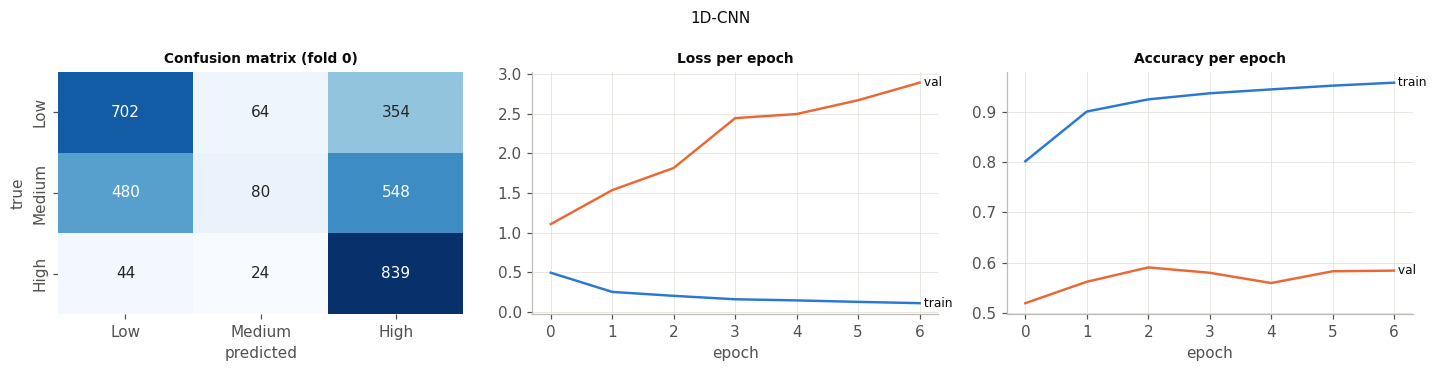


>>> 1D-CNN                 macro-F1 0.398 +/- 0.056 | acc 0.455 | params 116,483 | 135s (all folds)


In [ ]:
def build_cnn1d(shape, k):
    inp = keras.Input(shape); x = inp
    for f, ks, pool in ((64, 5, True), (128, 5, True), (128, 3, False)):
        x = layers.Conv1D(f, ks, padding="same")(x); x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
        if pool: x = layers.MaxPooling1D(2)(x)
    return keras.Model(inp, head(layers.GlobalAveragePooling1D()(x), k))

SEQ_MODELS["1D-CNN"] = (build_cnn1d, 1e-3)
run_keras("1D-CNN", build_cnn1d, "Sequence DL", X_seq, "seq", lr=1e-3, explain=True)

### 11.2 Simple RNN

**Objective:** read the window **step by step**, carrying a hidden state forward, so the model has a memory of what came before.

**Architecture:** two SimpleRNN layers (64 then 32 units) and the shared head.

**Why next:** it is the plain recurrent baseline and the reference point for LSTM and GRU. **Known weakness:** gradients shrink as they travel back through 100 steps (the *vanishing gradient* problem), so it often learns slowly or unstably. Watch the learning curve: it is usually the noisiest one.

===== Simple RNN: architecture =====


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 100, 51)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 100, 64)        │         7,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,835 (50.14 KB)

 Trainable params: 12,835 (50.14 KB)

 Non-trainable params: 0 (0.00 B)


===== Simple RNN: training on fold 0 (epoch log) =====
Epoch 1/40
83/83 - 12s - 142ms/step - accuracy: 0.5730 - loss: 0.9272 - val_accuracy: 0.4880 - val_loss: 1.0592
Epoch 2/40
83/83 - 2s - 19ms/step - accuracy: 0.7173 - loss: 0.6979 - val_accuracy: 0.4474 - val_loss: 1.2586
Epoch 3/40
83/83 - 2s - 18ms/step - accuracy: 0.7736 - loss: 0.5759 - val_accuracy: 0.4902 - val_loss: 1.2465
Epoch 4/40
83/83 - 2s - 19ms/step - accuracy: 0.8060 - loss: 0.5063 - val_accuracy: 0.5056 - val_loss: 1.2853
Epoch 5/40
83/83 - 2s - 19ms/step - accuracy: 0.8338 - loss: 0.4343 - val_accuracy: 0.5466 - val_loss: 1.4118
Epoch 6/40
83/83 - 2s - 19ms/step - accuracy: 0.8282 - loss: 0.4407 - val_accuracy: 0.5581 - val_loss: 1.2908
Epoch 7/40
83/83 - 2s - 19ms/step - accuracy: 0.8508 - loss: 0.4037 - val_accuracy: 0.5252 - val_loss: 1.3348

Trained 7 epochs, best epoch 1 (weights restored), 22s, 12,835 parameters

Fold-0 classification report: Simple RNN
              precision    recall  f1-score   support



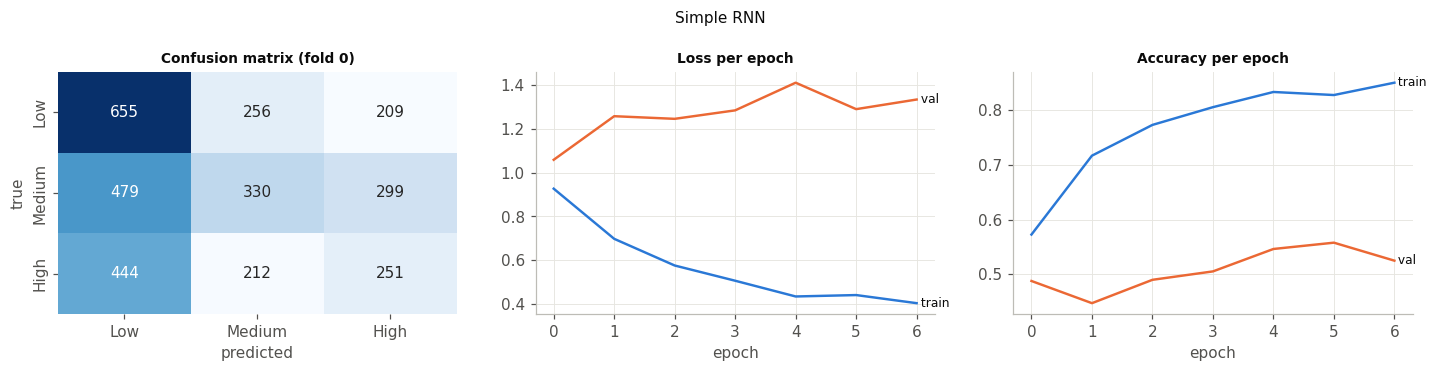


>>> Simple RNN             macro-F1 0.397 +/- 0.023 | acc 0.422 | params 12,835 | 135s (all folds)


In [ ]:
def build_rnn(shape, k):
    inp = keras.Input(shape)
    x = layers.SimpleRNN(64, return_sequences=True)(inp); x = layers.SimpleRNN(32)(x)
    return keras.Model(inp, head(x, k))

SEQ_MODELS["Simple RNN"] = (build_rnn, 1e-3)
run_keras("Simple RNN", build_rnn, "Sequence DL", X_seq, "seq", lr=1e-3, explain=True)

### 11.3 LSTM

**Objective:** a recurrent network with **gates** (input, forget, output) that decide what to remember and what to drop, so useful information survives across many steps.

**Architecture:** two LSTM layers (64 then 32 units) and the shared head.

**Why next:** it directly fixes the RNN's vanishing-gradient problem. In drowsiness data this matters because the signal is a slow build-up (eyes closing more often, longer), not one instant event. Compare its curve and score with the Simple RNN above; the parameter count is about 4× larger for the same width because of the gates.

===== LSTM: architecture =====


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 100, 51)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 100, 64)        │        29,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,419 (173.51 KB)

 Trainable params: 44,419 (173.51 KB)

 Non-trainable params: 0 (0.00 B)


===== LSTM: training on fold 0 (epoch log) =====
Epoch 1/40
83/83 - 8s - 92ms/step - accuracy: 0.6658 - loss: 0.7746 - val_accuracy: 0.5291 - val_loss: 1.1912
Epoch 2/40
83/83 - 1s - 17ms/step - accuracy: 0.8646 - loss: 0.3805 - val_accuracy: 0.4782 - val_loss: 1.5499
Epoch 3/40
83/83 - 1s - 14ms/step - accuracy: 0.8958 - loss: 0.2944 - val_accuracy: 0.5261 - val_loss: 1.8279
Epoch 4/40
83/83 - 1s - 14ms/step - accuracy: 0.9225 - loss: 0.2266 - val_accuracy: 0.5397 - val_loss: 1.7439
Epoch 5/40
83/83 - 1s - 14ms/step - accuracy: 0.9270 - loss: 0.2108 - val_accuracy: 0.4927 - val_loss: 2.0882
Epoch 6/40
83/83 - 1s - 14ms/step - accuracy: 0.9266 - loss: 0.2126 - val_accuracy: 0.4491 - val_loss: 2.4012
Epoch 7/40
83/83 - 1s - 14ms/step - accuracy: 0.9437 - loss: 0.1642 - val_accuracy: 0.5179 - val_loss: 2.0837

Trained 7 epochs, best epoch 1 (weights restored), 15s, 44,419 parameters

Fold-0 classification report: LSTM
              precision    recall  f1-score   support

         Low  

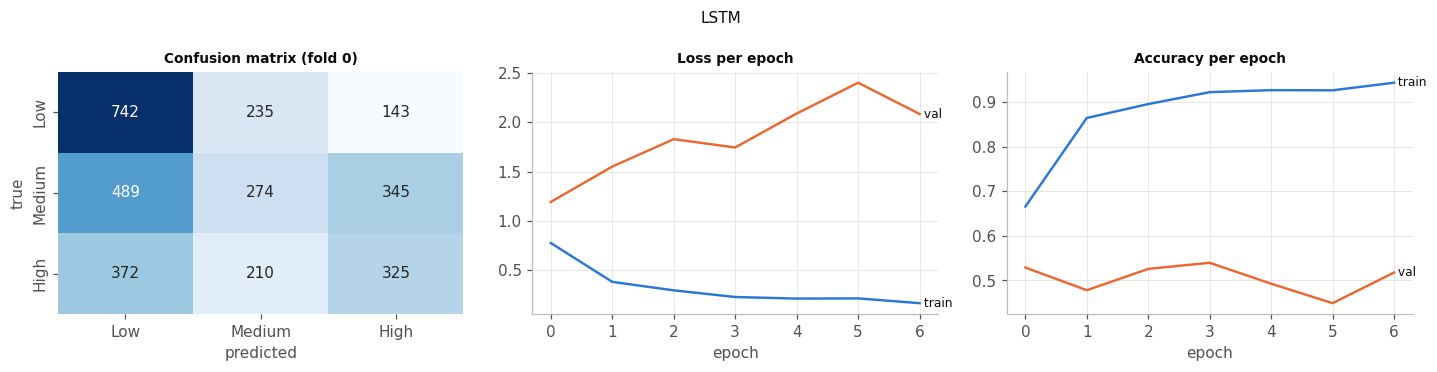


>>> LSTM                   macro-F1 0.406 +/- 0.043 | acc 0.418 | params 44,419 | 77s (all folds)


In [ ]:
def build_lstm(shape, k):
    inp = keras.Input(shape)
    x = layers.LSTM(64, return_sequences=True)(inp); x = layers.LSTM(32)(x)
    return keras.Model(inp, head(x, k))

SEQ_MODELS["LSTM"] = (build_lstm, 1e-3)
run_keras("LSTM", build_lstm, "Sequence DL", X_seq, "seq", lr=1e-3, explain=True)

### 11.4 GRU

**Objective:** a simplified LSTM with only two gates (update and reset) and no separate memory cell.

**Architecture:** two GRU layers (64 then 32 units) and the shared head.

**Why next:** it usually matches LSTM accuracy with about 25% fewer parameters and trains faster. The question for the comparison is whether the extra gate in LSTM buys anything on this dataset. (The ablation in Section 13 also uses the GRU, because it is fast and accurate.)

===== GRU: architecture =====


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 100, 51)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 100, 64)        │        22,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,179 (133.51 KB)

 Trainable params: 34,179 (133.51 KB)

 Non-trainable params: 0 (0.00 B)


===== GRU: training on fold 0 (epoch log) =====
Epoch 1/40
83/83 - 4s - 45ms/step - accuracy: 0.6016 - loss: 0.8816 - val_accuracy: 0.5043 - val_loss: 1.0714
Epoch 2/40
83/83 - 2s - 26ms/step - accuracy: 0.7781 - loss: 0.5613 - val_accuracy: 0.5889 - val_loss: 1.0951
Epoch 3/40
83/83 - 2s - 23ms/step - accuracy: 0.8546 - loss: 0.3854 - val_accuracy: 0.6137 - val_loss: 1.3036
Epoch 4/40
83/83 - 1s - 14ms/step - accuracy: 0.8897 - loss: 0.2951 - val_accuracy: 0.6248 - val_loss: 1.4933
Epoch 5/40
83/83 - 1s - 14ms/step - accuracy: 0.9095 - loss: 0.2460 - val_accuracy: 0.5962 - val_loss: 1.6268
Epoch 6/40
83/83 - 1s - 13ms/step - accuracy: 0.9264 - loss: 0.2052 - val_accuracy: 0.5979 - val_loss: 1.8636
Epoch 7/40
83/83 - 1s - 14ms/step - accuracy: 0.9371 - loss: 0.1790 - val_accuracy: 0.5440 - val_loss: 2.5031

Trained 7 epochs, best epoch 1 (weights restored), 13s, 34,179 parameters

Fold-0 classification report: GRU
              precision    recall  f1-score   support

         Low    

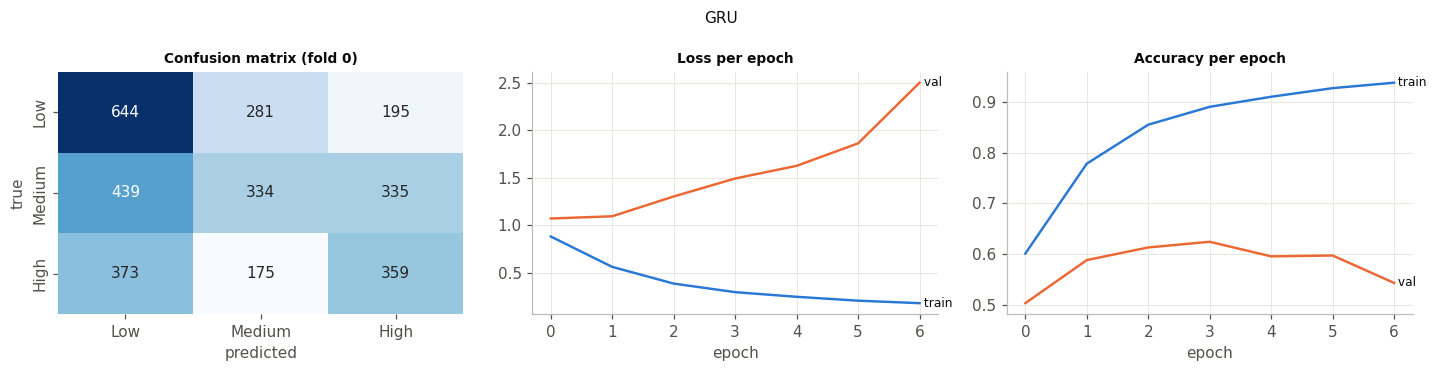


>>> GRU                    macro-F1 0.420 +/- 0.049 | acc 0.443 | params 34,179 | 73s (all folds)


In [ ]:
def build_gru(shape, k):
    inp = keras.Input(shape)
    x = layers.GRU(64, return_sequences=True)(inp); x = layers.GRU(32)(x)
    return keras.Model(inp, head(x, k))

SEQ_MODELS["GRU"] = (build_gru, 1e-3)
run_keras("GRU", build_gru, "Sequence DL", X_seq, "seq", lr=1e-3, explain=True)

### 11.5 Transformer

**Objective:** replace recurrence by **self-attention**: every time step looks directly at every other step and decides which ones matter. There is no step-by-step memory to degrade.

**Architecture:** a Dense layer projects each step to 64 dimensions, a learned **position embedding** is added (attention itself has no sense of order), then 2 blocks of [LayerNorm → 4-head self-attention → residual add → feed-forward → residual add], then GlobalAveragePooling and the shared head.

**Why here:** it is the modern state of the art for sequences. **Honest expectation:** transformers need a lot of data, and we have only 19 subjects, so it is kept small (lower learning rate 5e-4) and may *not* win. A reasoned negative result is a good result.

===== Transformer: architecture =====


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 100, 51)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 100, 64)   │      3,328 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_position_embed… │ (None, 100, 64)   │      6,400 │ dense[0][0]       │
│ (AddPositionEmbedd… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 100, 64)   │        128 │ add_position_emb… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 100, 64)   │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 100, 64)   │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 100, 64)   │          0 │ add_position_emb… │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 100, 64)   │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 100, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 100, 128)  │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 100, 64)   │      8,256 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 100, 64)   │          0 │ add[0][0],        │
│                     │                   │            │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 100, 64)   │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 100, 64)   │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 100, 64)   │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 100, 64)   │          0 │ add_1[0][0],      │
│                     │                   │            │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 100, 64)   │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 100, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 100, 128)  │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 81,155 (317.01 KB)

 Trainable params: 81,155 (317.01 KB)

 Non-trainable params: 0 (0.00 B)


===== Transformer: training on fold 0 (epoch log) =====
Epoch 1/40
83/83 - 36s - 435ms/step - accuracy: 0.6374 - loss: 0.8044 - val_accuracy: 0.5056 - val_loss: 1.1202
Epoch 2/40
83/83 - 1s - 15ms/step - accuracy: 0.8342 - loss: 0.4299 - val_accuracy: 0.5081 - val_loss: 1.4429
Epoch 3/40
83/83 - 1s - 14ms/step - accuracy: 0.8912 - loss: 0.2955 - val_accuracy: 0.5034 - val_loss: 1.9161
Epoch 4/40
83/83 - 1s - 14ms/step - accuracy: 0.9210 - loss: 0.2148 - val_accuracy: 0.4838 - val_loss: 2.3712
Epoch 5/40
83/83 - 1s - 14ms/step - accuracy: 0.9355 - loss: 0.1810 - val_accuracy: 0.4966 - val_loss: 2.5794
Epoch 6/40
83/83 - 1s - 14ms/step - accuracy: 0.9469 - loss: 0.1471 - val_accuracy: 0.5145 - val_loss: 2.8293
Epoch 7/40
83/83 - 1s - 14ms/step - accuracy: 0.9533 - loss: 0.1279 - val_accuracy: 0.5077 - val_loss: 2.9392

Trained 7 epochs, best epoch 1 (weights restored), 44s, 81,155 parameters

Fold-0 classification report: Transformer
              precision    recall  f1-score   support

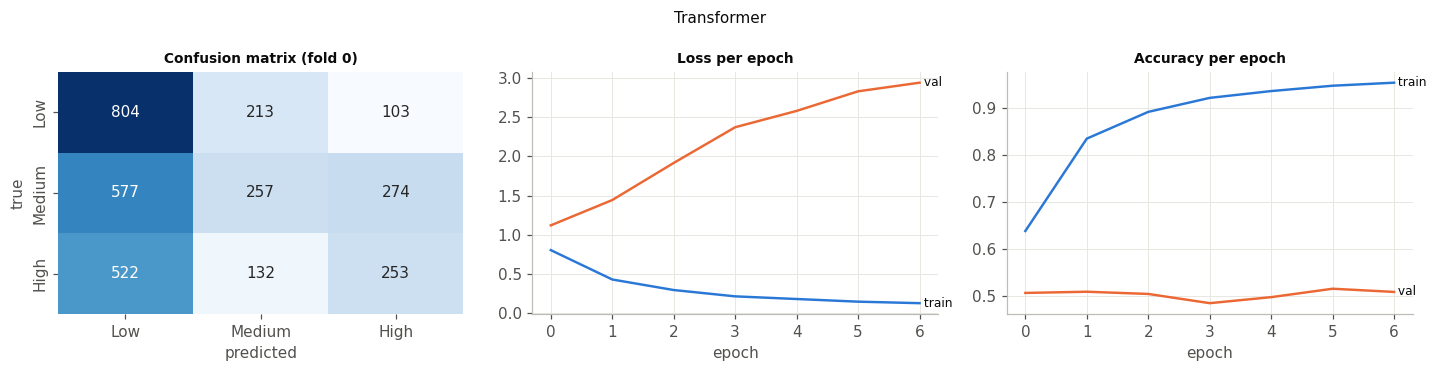


>>> Transformer            macro-F1 0.409 +/- 0.080 | acc 0.437 | params 81,155 | 232s (all folds)


In [ ]:
class AddPositionEmbedding(layers.Layer):
    def build(self, input_shape):
        self.pos = self.add_weight(shape=(1, input_shape[1], input_shape[2]), initializer="random_normal", trainable=True)
    def call(self, x): return x + self.pos

def build_transformer(shape, k, d_model=64, heads=4, blocks=2, ff=128, drop=0.1):
    inp = keras.Input(shape)
    x = AddPositionEmbedding()(layers.Dense(d_model)(inp))
    for _ in range(blocks):
        n = layers.LayerNormalization()(x)
        a = layers.MultiHeadAttention(num_heads=heads, key_dim=d_model // heads, dropout=drop)(n, n)
        x = layers.Add()([x, layers.Dropout(drop)(a)])
        f = layers.Dense(ff, activation="relu")(layers.LayerNormalization()(x)); f = layers.Dense(d_model)(layers.Dropout(drop)(f))
        x = layers.Add()([x, f])
    return keras.Model(inp, head(layers.GlobalAveragePooling1D()(layers.LayerNormalization()(x)), k))

SEQ_MODELS["Transformer"] = (build_transformer, 5e-4)
run_keras("Transformer", build_transformer, "Sequence DL", X_seq, "seq", lr=5e-4, explain=True)

### 11.6 CNN-BiLSTM (hybrid)

**Objective:** combine the strengths of two ideas: the CNN extracts **local patterns** and shortens the sequence, then a **bidirectional** LSTM reads those patterns forwards and backwards to model their order.

**Architecture:** Conv1D(64) → BatchNorm → MaxPool → Bidirectional LSTM(64) → shared head.

**Why last:** this CNN + recurrent hybrid is the design most often reported in the drowsiness literature, so it is the natural final model of the sequence family. Offline we can use both directions of the window; a real-time system could only use the forward one.

===== CNN-BiLSTM: architecture =====


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 100, 51)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 100, 64)        │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91,139 (356.01 KB)

 Trainable params: 91,011 (355.51 KB)

 Non-trainable params: 128 (512.00 B)


===== CNN-BiLSTM: training on fold 0 (epoch log) =====
Epoch 1/40
83/83 - 6s - 73ms/step - accuracy: 0.7428 - loss: 0.6151 - val_accuracy: 0.5312 - val_loss: 1.2572
Epoch 2/40
83/83 - 1s - 14ms/step - accuracy: 0.8933 - loss: 0.2805 - val_accuracy: 0.5175 - val_loss: 1.6433
Epoch 3/40
83/83 - 1s - 14ms/step - accuracy: 0.9294 - loss: 0.1958 - val_accuracy: 0.5410 - val_loss: 1.9359
Epoch 4/40
83/83 - 1s - 13ms/step - accuracy: 0.9386 - loss: 0.1681 - val_accuracy: 0.5684 - val_loss: 1.8764
Epoch 5/40
83/83 - 1s - 14ms/step - accuracy: 0.9483 - loss: 0.1414 - val_accuracy: 0.5650 - val_loss: 2.0362
Epoch 6/40
83/83 - 1s - 17ms/step - accuracy: 0.9560 - loss: 0.1236 - val_accuracy: 0.5389 - val_loss: 2.0419
Epoch 7/40
83/83 - 2s - 20ms/step - accuracy: 0.9646 - loss: 0.0972 - val_accuracy: 0.5564 - val_loss: 2.3193

Trained 7 epochs, best epoch 1 (weights restored), 16s, 91,139 parameters

Fold-0 classification report: CNN-BiLSTM
              precision    recall  f1-score   support

  

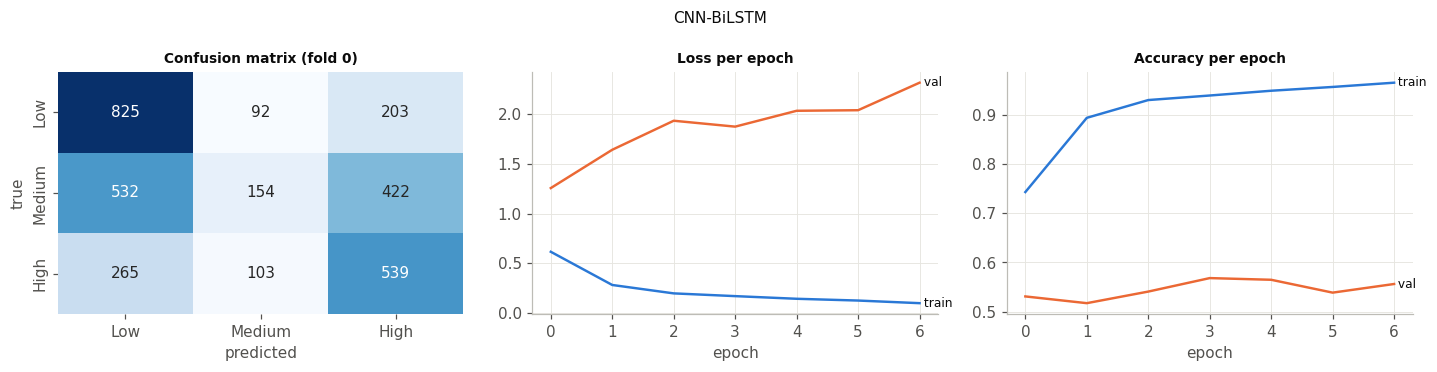


>>> CNN-BiLSTM             macro-F1 0.381 +/- 0.051 | acc 0.405 | params 91,139 | 93s (all folds)


In [ ]:
def build_cnn_bilstm(shape, k):
    inp = keras.Input(shape)
    x = layers.Conv1D(64, 5, padding="same", activation="relu")(inp); x = layers.BatchNormalization()(x); x = layers.MaxPooling1D(2)(x)
    x = layers.Bidirectional(layers.LSTM(64))(x)
    return keras.Model(inp, head(x, k))

SEQ_MODELS["CNN-BiLSTM"] = (build_cnn_bilstm, 1e-3)
run_keras("CNN-BiLSTM", build_cnn_bilstm, "Sequence DL", X_seq, "seq", lr=1e-3, explain=True)

In [ ]:
# ---- stage summary: everything trained so far (classical + ANN + sequence models) ----
_all = summarize(pd.DataFrame(RESULTS))
display(_all[["family", "macro_f1", "macro_f1_std", "accuracy", "bal_acc", "recall_top", "auc", "params", "train_s"]].round(3))

,family,macro_f1,macro_f1_std,accuracy,bal_acc,recall_top,auc,params,train_s
model,,,,,,,,,
XGBoost,ML,0.482,0.067,0.546,0.503,0.759,0.664,NaN,33.378
Random Forest,ML,0.480,0.077,0.569,0.520,0.794,0.711,NaN,46.996
RF (paper config),ML,0.461,0.056,0.518,0.480,0.715,0.693,NaN,6.927
GRU,Sequence DL,0.420,0.049,0.443,0.428,0.479,0.594,34179.0,12.408
Transformer,Sequence DL,0.409,0.080,0.437,0.418,0.462,0.591,81155.0,40.192
LSTM,Sequence DL,0.406,0.043,0.418,0.419,0.442,0.612,44419.0,13.094
1D-CNN,Sequence DL,0.398,0.056,0.455,0.436,0.769,0.642,116483.0,21.153
Simple RNN,Sequence DL,0.397,0.023,0.422,0.401,0.451,0.586,12835.0,23.352
CNN-BiLSTM,Sequence DL,0.381,0.051,0.405,0.409,0.551,0.612,91139.0,15.543


Tree-based ML (XGBoost, Random Forest, RF (paper config)) clearly dominates: All three sit at the very top of the table (macro_f1 0.461–0.482, auc 0.664–0.711), showing that tabular decision-tree ensembles handle your feature set much better than neural architectures.

Sequence DL (GRU, Transformer, LSTM, 1D-CNN, Simple RNN, CNN-BiLSTM) forms the middle tier: Led by GRU (macro_f1 0.420), these models beat linear/kernel/MLP baselines on macro_f1, with 1D-CNN standing out for high recall_top (0.769) and auc (0.642), and Simple RNN showing the lowest fold variance (0.023) among non-reference models.

## 12. Image models: VGG16 and InceptionV3


In [ ]:
# Image Model Settings
USE_IMAGENET = True
EPOCHS, BATCH, PATIENCE = 30, 64, 5
QUICK_MODE = False
if QUICK_MODE: EPOCHS = 3

## 1. Turn each window into an image

A window is a table of **100 time steps × 51 signals** (eye openness, mouth openness, head pose, facial action units, body pose...). We draw that table as a picture:

* **rows = time** (top = start of the 10 seconds), **columns = signals**;
* the value becomes a colour (viridis: dark purple = low, yellow = high). The colour range is **fixed** (−3 to +3, because the signals are already z-scored per subject in the main notebook), so nothing is computed from test data;
* each signal is drawn 2 pixels wide, so the final image is **100 × 102 × 3**.

A long eye closure or a head nod becomes a visible streak that a 2D convolution can detect. VGG16 needs at least 32×32 and InceptionV3 at least 75×75, so this size is fine without any resizing.

image tensor: (16013, 100, 102, 3) | 490 MB


NameError: name 'kss' is not defined

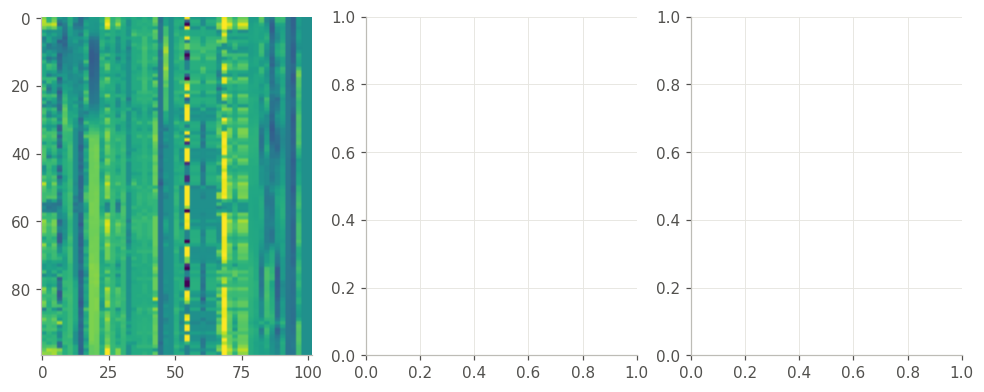

In [ ]:
LUT = (plt.get_cmap("viridis")(np.linspace(0, 1, 256))[:, :3] * 255).astype(np.uint8)   # 256 colours -> RGB

def windows_to_images(X, clip=3.0, rep=2, bs=1024):
    out = np.empty((len(X), X.shape[1], X.shape[2] * rep, 3), np.uint8)
    for i in range(0, len(X), bs):
        g = np.clip((X[i:i + bs] + clip) / (2 * clip), 0, 1)       # scale [-3, 3] -> [0, 1]
        g = np.repeat(g, rep, axis=2)                               # each signal 2 pixels wide
        out[i:i + bs] = LUT[np.round(g * 255).astype(np.uint8)]     # value -> colour
    return out

X_img = windows_to_images(X_seq)
IMG_SHAPE = X_img.shape[1:]
assert min(IMG_SHAPE[:2]) >= 75, "InceptionV3 needs images of at least 75 x 75"
print("image tensor:", X_img.shape, f"| {X_img.nbytes/1e6:.0f} MB")

rng = np.random.RandomState(1)
fig, axes = plt.subplots(1, K, figsize=(3.6 * K, 4))
for c, a in enumerate(axes):
    i = rng.choice(np.where(y == c)[0]); a.imshow(X_img[i], aspect="auto"); a.grid(False)
    a.set_title(f"{CLASS_NAMES[c]} (KSS {kss[i]:g})", fontsize=10); a.set_xlabel("signals"); a.set_ylabel("time (100 steps = 10 s)")
plt.tight_layout(); plt.show()

## 2. Shared helpers: training, evaluation, results

One small training function is used for **every** model in this notebook, so differences come from the model and not from the recipe: Adam optimiser, class weights (rare classes count more), and **early stopping** on a validation set made of whole subjects held out of the training fold. The test fold is never used for training or stopping.

**How to read the epoch log:** `accuracy`/`loss` = training data; `val_accuracy`/`val_loss` = held-out subjects (the honest numbers). If training keeps improving while validation stalls, the model is overfitting.

In [ ]:
import tensorflow as tf
tf.get_logger().setLevel("ERROR")
from tensorflow import keras
from tensorflow.keras import layers
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "none (training will be slow)")

RESULTS = []

def metrics(y_true, prob):
    pred = prob.argmax(1)
    m = dict(accuracy=accuracy_score(y_true, pred), bal_acc=balanced_accuracy_score(y_true, pred),
             macro_f1=f1_score(y_true, pred, average="macro", labels=range(K), zero_division=0),
             recall_top=recall_score(y_true, pred, labels=[K - 1], average="macro", zero_division=0))
    try:    m["auc"] = roc_auc_score(y_true, prob, multi_class="ovr", average="macro", labels=list(range(K))) if K > 2 else roc_auc_score(y_true, prob[:, 1])
    except ValueError: m["auc"] = np.nan
    return m

def explain_fold(label, y_true, prob, hist):
    """Classification report + confusion matrix + learning curves for one fold."""
    pred = prob.argmax(1)
    print(f"\nClassification report, fold 0: {label}")
    print(classification_report(y_true, pred, labels=list(range(K)), target_names=CLASS_NAMES, zero_division=0, digits=3))
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
    sns.heatmap(confusion_matrix(y_true, pred, labels=range(K)), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true"); ax[0].set_title("Confusion matrix")
    for a, key in ((ax[1], "loss"), (ax[2], "accuracy")):
        a.plot(hist[key], color="#2a78d6", lw=1.6, label="train"); a.plot(hist["val_" + key], color="#eb6834", lw=1.6, label="validation")
        a.set_title(key.capitalize() + " per epoch"); a.set_xlabel("epoch"); a.legend(frameon=False)
    plt.tight_layout(); plt.show()

def train_one(label, build_fn, Xtr, ytr, gtr, Xte, yte, fold, family, explain=False, lr=1e-3):
    keras.utils.set_random_seed(0)
    tr_i, va_i = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=0).split(Xtr, ytr, gtr))   # validation = unseen subjects
    classes = np.unique(ytr[tr_i]); cw = dict(zip(classes, compute_class_weight("balanced", classes=classes, y=ytr[tr_i])))
    model = build_fn(Xtr.shape[1:], K)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    h = model.fit(Xtr[tr_i], ytr[tr_i], validation_data=(Xtr[va_i], ytr[va_i]), epochs=EPOCHS, batch_size=BATCH, class_weight=cw,
                  verbose=2 if explain else 0, callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)])
    train_s = time.time() - t0
    t0 = time.time(); prob = model.predict(Xte, batch_size=256, verbose=0); infer_ms = (time.time() - t0) / len(Xte) * 1000
    RESULTS.append(dict(model=label, family=family, dataset="signal images", fold=fold, seed=0, **metrics(yte, prob),
                        params=model.count_params(), train_s=train_s, infer_ms=infer_ms))
    if explain:
        print(f"\nTrained {len(h.history['loss'])} epochs, best epoch {int(np.argmin(h.history['val_loss'])) + 1}, {train_s:.0f}s")
        explain_fold(label, yte, prob, h.history)
    keras.backend.clear_session()

def run_all_folds(label, build_fn, X, family="Image DL", scale=False, lr=1e-3):
    """Fold 0 with full details, then the remaining folds quietly. X = images or embeddings."""
    t_all = time.time()
    for fold, (tr, te) in enumerate(FOLDS):
        Xtr, Xte = X[tr], X[te]
        if scale: sc = StandardScaler().fit(Xtr); Xtr, Xte = sc.transform(Xtr).astype("float32"), sc.transform(Xte).astype("float32")
        train_one(label, build_fn, Xtr, y[tr], groups[tr], Xte, y[te], fold, family, explain=(fold == 0), lr=lr)
    d = pd.DataFrame(RESULTS); d = d[d.model == label]
    print(f"\n>>> {label}: macro-F1 {d.macro_f1.mean():.3f} +/- {d.macro_f1.std():.3f} | accuracy {d.accuracy.mean():.3f} | {time.time()-t_all:.0f}s (all folds)")

def head(x, k, units=64, drop=0.3):
    """Small classifier on top of features: Dropout -> Dense -> softmax."""
    x = layers.Dropout(drop)(x); x = layers.Dense(units, activation="relu")(x)
    return layers.Dense(k, activation="softmax")(x)

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Basic 2D CNN from scratch

**Objective:** the simplest image network, and the natural first step before the big pretrained ones. It learns its own filters from our signal images.

**Architecture:** three blocks of **Conv2D → BatchNorm → ReLU → MaxPool** with 32, 64 and 128 filters, then global average pooling and a small classifier.

| Layer | What it does |
|---|---|
| `Conv2D(3×3)` | Small filters slide over the image and respond to local patterns (a streak = a long eye closure) |
| `BatchNormalization` | Keeps values well scaled, so training is faster and stabler |
| `ReLU` | Non-linearity; without it stacked layers collapse into one linear map |
| `MaxPooling2D(2)` | Keeps the strongest value in each 2×2 block: halves the image size, cheaper, tolerant to small shifts |
| `GlobalAveragePooling2D` | One average per feature map, so we get a vector without a huge Dense layer |
| `Dropout` / `Dense(softmax)` | Reduces overfitting / outputs one probability per class |

**Why now:** it shows what a convolution network can learn *from our data alone*. VGG16 and InceptionV3 below have to beat this to justify their size.

===== 2D CNN: architecture =====


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 100, 102, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 100, 102, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 100, 102, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 100, 102, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 100, 102, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 50, 51, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 50, 51, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 50, 51, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 50, 51, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 25, 25, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 25, 25, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 25, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,595 (400.76 KB)

 Trainable params: 102,147 (399.01 KB)

 Non-trainable params: 448 (1.75 KB)


===== 2D CNN: training (epoch log for fold 0) =====
Epoch 1/30
165/165 - 29s - 178ms/step - accuracy: 0.5766 - loss: 0.9086 - val_accuracy: 0.3308 - val_loss: 1.5203
Epoch 2/30
165/165 - 5s - 28ms/step - accuracy: 0.7184 - loss: 0.6701 - val_accuracy: 0.3218 - val_loss: 1.5664
Epoch 3/30
165/165 - 5s - 28ms/step - accuracy: 0.7798 - loss: 0.5501 - val_accuracy: 0.3496 - val_loss: 1.2162
Epoch 4/30
165/165 - 5s - 29ms/step - accuracy: 0.8147 - loss: 0.4762 - val_accuracy: 0.3175 - val_loss: 1.4886
Epoch 5/30
165/165 - 5s - 28ms/step - accuracy: 0.8392 - loss: 0.4196 - val_accuracy: 0.3342 - val_loss: 4.3748
Epoch 6/30
165/165 - 5s - 28ms/step - accuracy: 0.8518 - loss: 0.3806 - val_accuracy: 0.4513 - val_loss: 1.7007
Epoch 7/30
165/165 - 5s - 29ms/step - accuracy: 0.8610 - loss: 0.3618 - val_accuracy: 0.4936 - val_loss: 1.2482
Epoch 8/30
165/165 - 5s - 29ms/step - accuracy: 0.8719 - loss: 0.3363 - val_accuracy: 0.3701 - val_loss: 3.5907

Trained 8 epochs, best epoch 3, 64s

Classificat

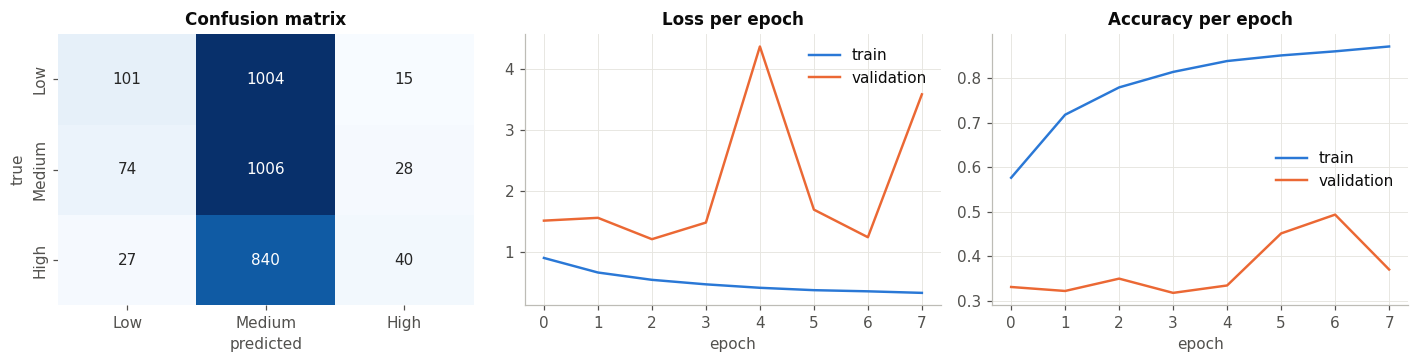


>>> 2D CNN (from scratch): macro-F1 0.232 +/- 0.108 | accuracy 0.353 | 324s (all folds)


In [ ]:
def build_cnn2d(shape, k):
    inp = keras.Input(shape, dtype="uint8")
    x = layers.Rescaling(1 / 255.0)(inp)                       # pixel 0..255 -> 0..1
    for f in (32, 64, 128):
        x = layers.Conv2D(f, 3, padding="same")(x); x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x); x = layers.MaxPooling2D(2)(x)
    return keras.Model(inp, head(layers.GlobalAveragePooling2D()(x), k))

print("===== 2D CNN: architecture ====="); build_cnn2d(IMG_SHAPE, K).summary(); keras.backend.clear_session()
print("\n===== 2D CNN: training (epoch log for fold 0) =====")
run_all_folds("2D CNN (from scratch)", build_cnn2d, X_img)

## 4. VGG16 (frozen, transfer learning)

**What VGG16 is:** a famous 2014 network: **13 convolution layers (all 3×3) in 5 blocks, each block ending in max-pooling**. Simple and deep (about 14.7 million parameters in the convolution body).

**Transfer learning in three steps:**
1. Load VGG16 with **ImageNet weights** (it already learned edges, textures, shapes from 1.2 million photos) and **drop its original classifier** (`include_top=False`).
2. **Freeze** it and pass every signal image through it once. Each image becomes a vector of **512 numbers** (`pooling="avg"` averages the last feature maps). These vectors are called *embeddings*.
3. Train only a **small classifier** (our `head`) on the embeddings. That is quick, and with little data it is safer than retraining 14 million weights.

The pretrained weights are *not changed*. The embeddings do not depend on the fold, so they are computed once; the scaler for the classifier is fit on the training fold only.

In [ ]:
weights = "imagenet" if USE_IMAGENET else None
vgg = keras.applications.VGG16(include_top=False, weights=weights, input_shape=IMG_SHAPE, pooling="avg")
vgg.trainable = False
vgg.summary()          # the VGG16 body: 13 Conv2D layers + 5 MaxPooling2D layers

t0 = time.time()
emb_vgg = np.concatenate([vgg.predict(keras.applications.vgg16.preprocess_input(X_img[i:i + 128].astype("float32")), verbose=0)
                          for i in range(0, len(X_img), 128)])
print("\nVGG16 embeddings:", emb_vgg.shape, f"({time.time()-t0:.0f}s)   <- one 512-number vector per window")
keras.backend.clear_session()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 100, 102, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 100, 102, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 100, 102, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 50, 51, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 50, 51, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 50, 51, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 25, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 25, 25, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 25, 25, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 25, 25, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 12, 12, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 6, 6, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)


VGG16 embeddings: (16013, 512) (42s)   <- one 512-number vector per window


===== Classifier on VGG16 embeddings: architecture =====


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,883 (292.51 KB)

 Trainable params: 74,499 (291.01 KB)

 Non-trainable params: 384 (1.50 KB)


===== VGG16 (frozen) + classifier: training (epoch log for fold 0) =====
Epoch 1/30
165/165 - 11s - 69ms/step - accuracy: 0.4810 - loss: 1.0663 - val_accuracy: 0.4658 - val_loss: 1.0067
Epoch 2/30
165/165 - 1s - 4ms/step - accuracy: 0.6158 - loss: 0.8457 - val_accuracy: 0.4893 - val_loss: 1.0196
Epoch 3/30
165/165 - 1s - 4ms/step - accuracy: 0.6751 - loss: 0.7460 - val_accuracy: 0.4855 - val_loss: 1.0568
Epoch 4/30
165/165 - 1s - 4ms/step - accuracy: 0.7100 - loss: 0.6835 - val_accuracy: 0.4949 - val_loss: 1.0756
Epoch 5/30
165/165 - 1s - 4ms/step - accuracy: 0.7421 - loss: 0.6209 - val_accuracy: 0.4709 - val_loss: 1.1467
Epoch 6/30
165/165 - 1s - 6ms/step - accuracy: 0.7642 - loss: 0.5716 - val_accuracy: 0.4769 - val_loss: 1.2039

Trained 6 epochs, best epoch 1, 15s

Classification report, fold 0: VGG16 (frozen) + classifier
              precision    recall  f1-score   support

         Low      0.383     0.549     0.452      1120
      Medium      0.303     0.192     0.235      110

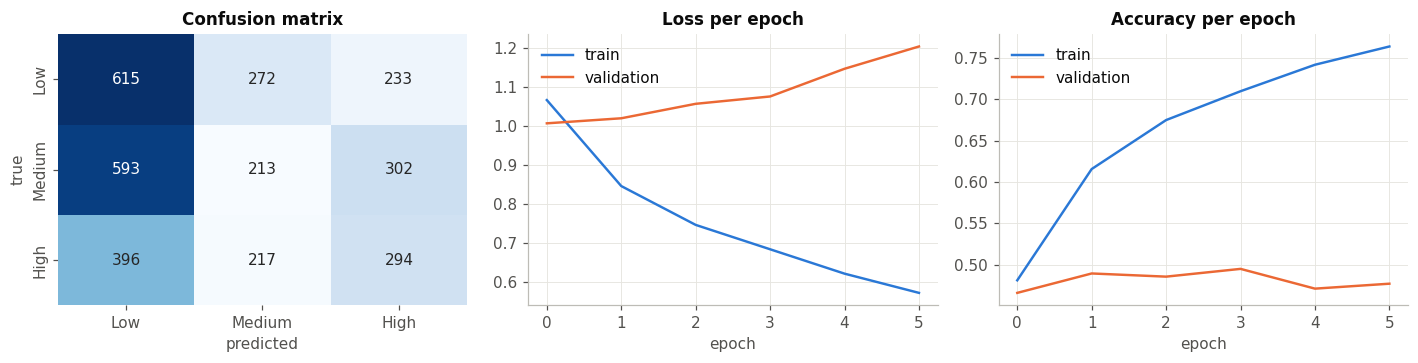


>>> VGG16 (frozen) + classifier: macro-F1 0.378 +/- 0.046 | accuracy 0.398 | 73s (all folds)


In [ ]:
def build_embedding_head(shape, k):
    inp = keras.Input(shape); x = inp
    for units, drop in ((128, 0.3), (64, 0.2)):
        x = layers.Dense(units)(x); x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x); x = layers.Dropout(drop)(x)
    return keras.Model(inp, layers.Dense(k, activation="softmax")(x))

print("===== Classifier on VGG16 embeddings: architecture ====="); build_embedding_head((emb_vgg.shape[1],), K).summary(); keras.backend.clear_session()
print("\n===== VGG16 (frozen) + classifier: training (epoch log for fold 0) =====")
run_all_folds("VGG16 (frozen) + classifier", build_embedding_head, emb_vgg, scale=True)

## 5. InceptionV3 (frozen, transfer learning)

**What InceptionV3 is:** a 2015 network built from **inception modules**. Instead of choosing one filter size, each module runs **1×1, 3×3 and 5×5 (factorised) convolutions and pooling in parallel** and concatenates the results, so it sees patterns at several scales at once. It is deeper than VGG16 but has fewer parameters (about 21.8 million), because the 1×1 convolutions shrink the data before the expensive ones.

| | VGG16 | InceptionV3 |
|---|---|---|
| Design | Plain stack of 3×3 convolutions | Parallel multi-scale branches (inception modules) |
| Embedding size | 512 | 2048 |
| Idea | Go deeper, keep it simple | Look at several scales at once, stay efficient |

**Same method as VGG16:** frozen ImageNet weights → embeddings (2048 numbers per window) → small trained classifier. The only differences are the backbone and its own `preprocess_input` (it scales pixels to −1…1).

In [ ]:
inc = keras.applications.InceptionV3(include_top=False, weights=weights, input_shape=IMG_SHAPE, pooling="avg")
inc.trainable = False
n_modules = sum(l.name.startswith("mixed") and "_" not in l.name for l in inc.layers)
print(f"InceptionV3 body: {len(inc.layers)} layers, {inc.count_params():,} parameters, {n_modules} inception modules (mixed0 ... mixed10)")

t0 = time.time()
emb_inc = np.concatenate([inc.predict(keras.applications.inception_v3.preprocess_input(X_img[i:i + 128].astype("float32")), verbose=0)
                          for i in range(0, len(X_img), 128)])
print("InceptionV3 embeddings:", emb_inc.shape, f"({time.time()-t0:.0f}s)   <- one 2048-number vector per window")
keras.backend.clear_session()

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
InceptionV3 body: 312 layers, 21,802,784 parameters, 11 inception modules (mixed0 ... mixed10)
InceptionV3 embeddings: (16013, 2048) (75s)   <- one 2048-number vector per window


===== Classifier on InceptionV3 embeddings: architecture =====


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 271,491 (1.04 MB)

 Trainable params: 271,107 (1.03 MB)

 Non-trainable params: 384 (1.50 KB)


===== InceptionV3 (frozen) + classifier: training (epoch log for fold 0) =====
Epoch 1/30
165/165 - 8s - 49ms/step - accuracy: 0.4606 - loss: 1.0949 - val_accuracy: 0.4047 - val_loss: 1.1631
Epoch 2/30
165/165 - 1s - 4ms/step - accuracy: 0.5719 - loss: 0.9181 - val_accuracy: 0.3748 - val_loss: 1.2164
Epoch 3/30
165/165 - 1s - 4ms/step - accuracy: 0.6225 - loss: 0.8322 - val_accuracy: 0.3953 - val_loss: 1.2363
Epoch 4/30
165/165 - 1s - 4ms/step - accuracy: 0.6631 - loss: 0.7597 - val_accuracy: 0.4107 - val_loss: 1.2711
Epoch 5/30
165/165 - 1s - 4ms/step - accuracy: 0.6977 - loss: 0.6935 - val_accuracy: 0.4291 - val_loss: 1.3230
Epoch 6/30
165/165 - 1s - 4ms/step - accuracy: 0.7288 - loss: 0.6409 - val_accuracy: 0.4017 - val_loss: 1.4277

Trained 6 epochs, best epoch 1, 12s

Classification report, fold 0: InceptionV3 (frozen) + classifier
              precision    recall  f1-score   support

         Low      0.346     0.378     0.361      1120
      Medium      0.261     0.218     0.2

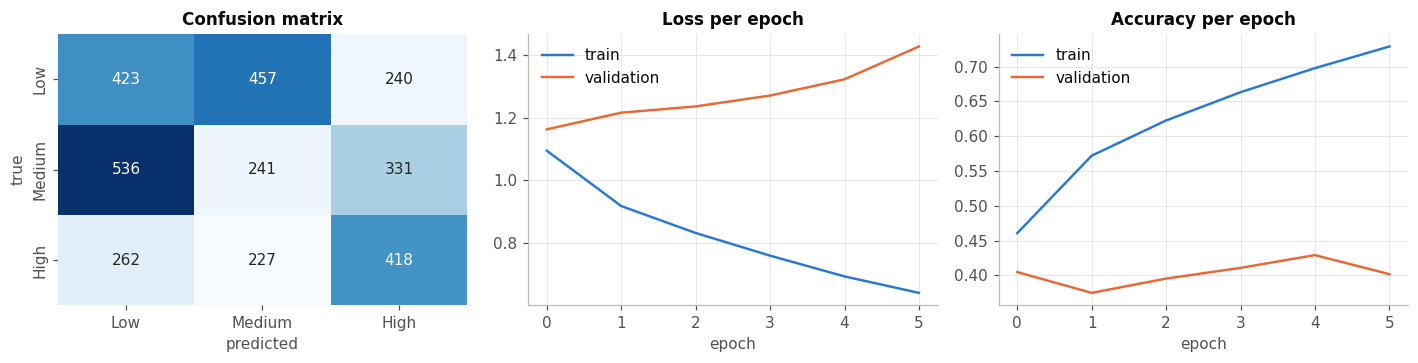


>>> InceptionV3 (frozen) + classifier: macro-F1 0.368 +/- 0.027 | accuracy 0.385 | 70s (all folds)


In [ ]:
print("===== Classifier on InceptionV3 embeddings: architecture ====="); build_embedding_head((emb_inc.shape[1],), K).summary(); keras.backend.clear_session()
print("\n===== InceptionV3 (frozen) + classifier: training (epoch log for fold 0) =====")
run_all_folds("InceptionV3 (frozen) + classifier", build_embedding_head, emb_inc, scale=True)

## 6. Comparison

The image models are merged with the results of the main notebook (`results/all_fold_results.csv`) if that file exists. The `dataset` column says what each model saw (window features, signal sequences, or signal images).

results/all_fold_results.csv not found: showing only the image models.


,family,dataset,macro_f1,macro_f1_std,accuracy,bal_acc,recall_top,auc,params,train_s
model,,,,,,,,,,
VGG16 (frozen) + classifier,Image DL,signal images,0.378,0.046,0.398,0.380,0.425,0.560,74883.0,11.896
InceptionV3 (frozen) + classifier,Image DL,signal images,0.368,0.027,0.385,0.371,0.421,0.551,271491.0,11.613
2D CNN (from scratch),Image DL,signal images,0.232,0.108,0.353,0.352,0.077,0.590,102595.0,57.792


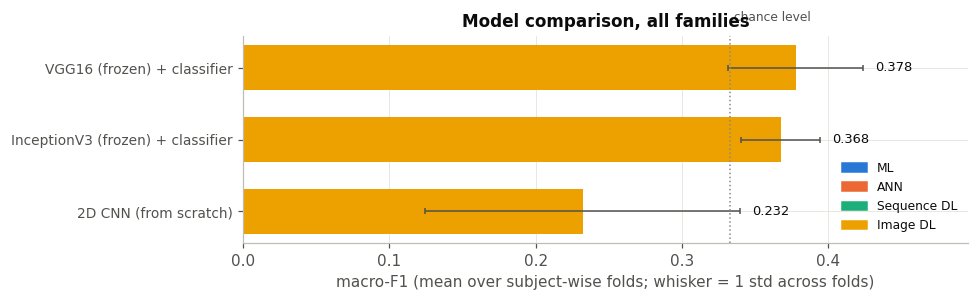

In [ ]:
new = pd.DataFrame(RESULTS); new.to_csv(OUT_DIR / "image_models_fold_results.csv", index=False)
prev_path = OUT_DIR / "all_fold_results.csv"
if prev_path.exists():
    prev = pd.read_csv(prev_path); prev = prev[~prev.model.isin(new.model.unique())]; res = pd.concat([prev, new], ignore_index=True)
else:
    print("results/all_fold_results.csv not found: showing only the image models."); res = new
res.to_csv(OUT_DIR / "all_fold_results_with_images.csv", index=False)

g = res.groupby("model")
SUM = g[["accuracy", "bal_acc", "macro_f1", "recall_top", "auc"]].mean()
SUM["macro_f1_std"] = g["macro_f1"].std()
for c in ("params", "train_s"): SUM[c] = g[c].mean()
SUM["family"] = g["family"].first(); SUM["dataset"] = g["dataset"].first()
SUM = SUM.sort_values("macro_f1", ascending=False)
display(SUM[["family", "dataset", "macro_f1", "macro_f1_std", "accuracy", "bal_acc", "recall_top", "auc", "params", "train_s"]].round(3))

COL = {"ML": "#2a78d6", "ANN": "#eb6834", "Sequence DL": "#1baf7a", "Image DL": "#eda100"}
order = SUM.index[::-1]
fig, ax = plt.subplots(figsize=(9, 0.42 * len(order) + 1.6))
for i, m in enumerate(order):
    r = SUM.loc[m]; sd = 0 if np.isnan(r.macro_f1_std) else r.macro_f1_std
    ax.barh(i, r.macro_f1, xerr=sd, height=0.62, color=COL.get(r.family, "#999"), error_kw=dict(ecolor=INK2, lw=1, capsize=2))
    ax.text(r.macro_f1 + sd + 0.008, i, f"{r.macro_f1:.3f}", va="center", fontsize=8.5)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=9); ax.set_xlim(0, min(1.0, SUM.macro_f1.max() * 1.18 + 0.05))
ax.axvline(1 / K, color="#8a8984", lw=1, ls=":"); ax.text(1 / K, len(order) - 0.35, " chance level", fontsize=8, color=INK2)
ax.set_xlabel("macro-F1 (mean over subject-wise folds; whisker = 1 std across folds)"); ax.set_title("Model comparison, all families")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COL.values()], COL.keys(), frameon=False, loc="lower right", fontsize=8)
plt.tight_layout(); fig.savefig(OUT_DIR / "fig_model_ranking_with_images.png", dpi=150, bbox_inches="tight"); plt.show()

Best overall macro-F1: VGG16 (frozen) + classifier achieved the highest mean macro-F1 at 0.378 ($\pm$ 0.046), along with the highest accuracy (0.398), balanced accuracy (0.380), and top recall (0.425).
